# Paper replication and new gene-model comparisons

This notebook compares classifiers on the paper's six genes, broader gene sets,
and model-specific subsets selected from training data.

First, redraw Figure 1B/C/D/F from the supplied data. Next, compare models on
the same six-gene matrices. Then compare 142 DE genes with all variable genes,
and run selection using the paper rule and fivefold CV, followed by a separate
refinement that allows additions, removals, and replacements of selected genes.
One shared model screen combines nine LazyPredict classifiers with XGBoost
and a small neural network. The GFS section reuses these same classifier
settings and evaluates the selected subsets.

## Read the result labels

| Label | Meaning | AUC plot mark |
|---|---|---|
| **Paper reported** | AUC values from `ml_auc.txt`; these classifiers are not refitted here. | Dark diamond (training/test) or triangle (validation) |
| **Paper replica** | Python scores from the reconstructed R six-gene GLM and its original VST inputs. | Dark diamond/triangle and a shaded row labeled paper replica |
| **New** | A classifier fitted in this notebook. | Blue circle (training/test) or triangle (validation) |

In AUC plots, open marks show training AUC, filled circles/diamonds show test AUC,
and filled triangles show validation AUC. The six-gene and broad-gene panels sort rows
from highest to lowest test AUC; GFS panels use one common model order. A higher test rank does not prove an improvement.
These test participants have already been examined during model development.
All new models are fitted on training samples only; the same fits score test and
validation samples. Validation does not select settings or change the row order.

## What differs from the paper?

| Comparison | Input and preprocessing | Model difference |
|---|---|---|
| Same six genes | Same 130 training, 61 test, and 60 validation samples; same original split-specific VST values | Paper GLM has no intercept or penalty. Four new logistic GLMs share one solver and a fitted intercept. Their penalties are none, L2, L1, and elastic net. The shared screen adds nine LazyPredict defaults, XGBoost, and a small neural network. |
| DE versus all genes | 142 or 52,990 genes; both use a VST fitted on training samples | All screened classifiers use the same settings in both input sets. |

The paper reports **113 DE candidates**. Its available filter returns **142**,
including an audit with the reported R and DESeq2 versions. The 113 gene IDs remain
unavailable. Thus, the broad-input experiment cannot reproduce those paper inputs.
The final six gene IDs are known. GFS selected those six genes; its final classifier
is a binomial-logit GLM without an intercept or penalty.

**Terms:** DE means differentially expressed. VST is a variance-stabilizing
transformation of counts. ROC AUC measures how well scores rank positive above
negative samples. An intercept is a fitted constant in the log odds. L2
regularization reduces large coefficients. L1 can set coefficients to zero.
Elastic net combines L1 and L2. An expression interaction means that
one gene's predictive effect depends on another gene's expression.

Linear classifiers do not contain interactions unless we add interaction terms.
Nonlinear model performance alone cannot establish genetic or causal epistasis.

Run all cells with the **cfRNA TB (Python)** kernel. Install packages from
`Scripts_For_Manuscript/gene_interactions.requirements.txt` if needed.
Current outputs go to `Figure_Output/Gene_Interactions/focused/`.
Earlier exports remain in the parent directory.

Sources: [paper](https://doi.org/10.1038/s41467-024-49245-6),
[original Figure 1 code](Figure_1.ipynb),
[input audit](../Files_For_Manuscript/gene_interactions_reference/paper_input_audit/README.md).

## 1. Set paths and plot style

Load the packages. Use one seed and one output folder. Save the package versions to help reproduce the run.

In [1]:
import hashlib
import json
import warnings
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from joblib import Parallel, delayed, parallel_config
from lazypredict.Supervised import LazyClassifier
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from scipy.special import expit
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import log_loss, roc_auc_score, roc_curve
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from threadpoolctl import threadpool_limits
from xgboost import XGBClassifier

SEED = 87
current = Path.cwd().resolve()
REPOSITORY = next(
    path
    for path in [current, *current.parents]
    if (path / "Files_For_Manuscript/counts.train.tsv").is_file()
)
DATA = REPOSITORY / "Files_For_Manuscript"
REFERENCE = DATA / "gene_interactions_reference"
PAPER_REFERENCE = DATA / "gene_cutoff_reference/paper_model"
OUTPUT = REPOSITORY / "Figure_Output/Gene_Interactions/focused"
OUTPUT.mkdir(parents=True, exist_ok=True)
PAPER_COLOR, NEW_COLOR = "#303030", "#386A87"
sns.set_theme(style="ticks", context="paper")
plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.labelsize": 10,
        "axes.titlesize": 11,
        "axes.titlepad": 10,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "figure.dpi": 110,
        "savefig.dpi": 300,
        "pdf.fonttype": 42,
    }
)


def save_figure(figure, name):
    for suffix in ["png", "pdf"]:
        figure.savefig(OUTPUT / f"{name}.{suffix}", bbox_inches="tight")


def check_hashes(expected_hashes):
    for relative_path, expected in expected_hashes.items():
        actual = hashlib.sha256((REPOSITORY / relative_path).read_bytes()).hexdigest()
        assert actual == expected, f"Reference input changed: {relative_path}"


package_versions = {
    name: version(name)
    for name in ["numpy", "pandas", "scipy", "scikit-learn", "lazypredict", "joblib", "xgboost-cpu"]
}
(OUTPUT / "package_versions.json").write_text(json.dumps(package_versions, indent=2))

165

## 2. Load samples and reference data

Read the count matrices and match rows by sample ID. Each model receives samples
in rows and genes in columns. Check that the three sample sets do not overlap.
The pooled samples are used only for the descriptive Figure 1 redraws.

In [2]:
def load_split(split):
    metadata = pd.read_csv(
        DATA / f"metadata.{split}.tsv", sep="\t", index_col="sample_id"
    )
    counts = pd.read_csv(DATA / f"counts.{split}.tsv", sep="\t", index_col=0).T
    assert metadata.index.is_unique and counts.index.is_unique
    assert counts.columns.is_unique
    assert set(counts.index) == set(metadata.index)
    counts = counts.loc[metadata.index].astype(np.int32)
    assert (counts.to_numpy() >= 0).all()
    assert set(metadata["tb"]) == {"negative", "positive"}
    return counts, metadata


train_counts, train_metadata = load_split("train")
test_counts, test_metadata = load_split("test")
validation_counts, validation_metadata = load_split("val")
assert train_counts.columns.equals(test_counts.columns)
assert train_counts.columns.equals(validation_counts.columns)
assert set(train_counts.index).isdisjoint(test_counts.index)
assert set(train_counts.index).isdisjoint(validation_counts.index)
assert set(test_counts.index).isdisjoint(validation_counts.index)

counts_all = pd.concat([train_counts, test_counts, validation_counts])
metadata_all = pd.concat([train_metadata, test_metadata, validation_metadata])
metadata_all["country"] = metadata_all["site"].replace(
    {"Mulago": "Uganda", "Kisenyi": "Uganda"}
)

cohort_summary = pd.crosstab(metadata_all["cohort"], metadata_all["tb"])
cohort_summary["Total"] = cohort_summary.sum(axis=1)
reference = json.loads((REFERENCE / "reference.json").read_text())
check_hashes(reference["input_sha256"])
training_de_genes = pd.read_csv(
    REFERENCE / "training_de_genes.tsv", sep="\t", index_col="gene_id"
)
assert (training_de_genes.padj < 0.05).all()
assert (training_de_genes.baseMean > 100).all()
split_metadata = {
    "train": train_metadata, "test": test_metadata, "val": validation_metadata
}
split_labels = {
    split: metadata.tb.eq("positive").astype(int).to_numpy()
    for split, metadata in split_metadata.items()
}
y_train, y_test = split_labels["train"], split_labels["test"]
SPLIT_NAMES = {"train": "Training", "test": "Test", "val": "Validation"}
display(cohort_summary)

tb,negative,positive,Total
cohort,,,
GHL,36,57,93
R2D2,48,50,98
TBSQUARE,25,35,60


### Define the count transformation

Apply the supplied DESeq2 dispersion trend and median-ratio reference. This
Python function implements the parametric VST. The calling cell states whether
the reference uses pooled samples or training samples. Counts already measure
RNA abundance. Normalization adjusts sample scale; VST reduces the dependence
of variance on mean abundance. The result is a transformed expression value,
not a new measurement or a gene coefficient.

This Python function is used for the descriptive heatmap and the broad-input
comparison. The six-gene paper comparison instead loads VST values exported
from R, as described in section 4.

In [3]:
def reference_log_means(reference_counts):
    """DESeq2's ratio estimator uses genes positive in every reference sample."""
    positive_genes = reference_counts.columns[(reference_counts > 0).all(axis=0)]
    return np.log(reference_counts[positive_genes]).mean(axis=0)


def variance_stabilize(counts, log_means, coefficients):
    """Apply a fixed DESeq2 reference and parametric dispersion trend."""
    ratios = np.log(counts[log_means.index].replace(0, np.nan)).subtract(log_means)
    size_factors = np.exp(ratios.median(axis=1))
    assert np.isfinite(size_factors).all() and (size_factors > 0).all()
    normalized = counts.div(size_factors, axis=0)
    asymptotic_dispersion = coefficients["asymptDisp"]
    extra_poisson = coefficients["extraPois"]
    dispersion_counts = asymptotic_dispersion * normalized
    transformed = np.log2(
        (
            1
            + extra_poisson
            + 2 * dispersion_counts
            + 2 * np.sqrt(dispersion_counts * (1 + extra_poisson + dispersion_counts))
        )
        / (4 * asymptotic_dispersion)
    )
    assert np.isfinite(transformed.to_numpy()).all()
    return transformed

## 3. Redraw the original descriptive panels

### Figure 1B: RNA sources

Average the existing plasma fractions in `Files_For_Manuscript/discovery_cell_types.tsv`
within each cohort. These values estimate RNA contributions. They are not cell counts. This panel uses paper
source data; it does not fit a new prediction model.

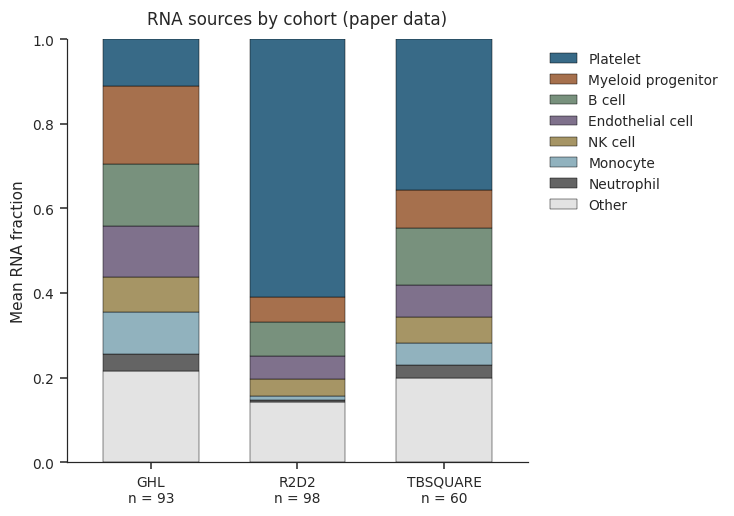

In [4]:
cell_fractions = pd.read_csv(
    DATA / "discovery_cell_types.tsv", sep="\t", index_col="sample_id"
)
cell_fractions = cell_fractions.loc[metadata_all.index]
assert np.allclose(cell_fractions.sum(axis=1), 1)

cell_names = {
    "Platelet": "Platelet",
    "Myeloid.progenitor": "Myeloid progenitor",
    "B.cell": "B cell",
    "Endothelial.cell": "Endothelial cell",
    "NK.Cell": "NK cell",
    "Monocyte": "Monocyte",
    "neutrophil": "Neutrophil",
}
cell_plot_data = cell_fractions[list(cell_names)].rename(columns=cell_names)
cell_plot_data["Other"] = cell_fractions.drop(columns=list(cell_names)).sum(axis=1)
cohort_fractions = (
    cell_plot_data.groupby(metadata_all["cohort"])
    .mean()
    .loc[["GHL", "R2D2", "TBSQUARE"]]
)
assert np.allclose(cohort_fractions.sum(axis=1), 1)

figure, axis = plt.subplots(figsize=(6.8, 4.8))
cohort_fractions.iloc[:, ::-1].plot.bar(
    stacked=True,
    ax=axis,
    width=0.65,
    edgecolor="black",
    linewidth=0.3,
    color=[
        "#386A87",
        "#A6704D",
        "#78917D",
        "#7F718C",
        "#A69565",
        "#91B2BE",
        "#646464",
        "#E3E3E3",
    ][::-1],
)
axis.set_xticklabels(["GHL\nn = 93", "R2D2\nn = 98", "TBSQUARE\nn = 60"], rotation=0)
axis.set(
    xlabel="",
    ylabel="Mean RNA fraction",
    ylim=(0, 1),
    title="RNA sources by cohort (paper data)",
)
handles, labels = axis.get_legend_handles_labels()
axis.legend(
    handles[::-1],
    labels[::-1],
    title="",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)
axis.grid(False)
figure.tight_layout()
save_figure(figure, "figure_1B_cell_origins")
plt.show()
cohort_fractions.to_csv(OUTPUT / "figure_1B_cell_origins.csv")

### Figure 1C: expression heatmap

Select genes with adjusted P below 0.05 from the supplied pooled DESeq2 table.
Apply the pooled VST, then standardize each gene for display. Cluster samples
and genes by correlation. These pooled labels do not select classifier inputs.

/local/workdir/amz63/cfRNA_TB/.venv/lib/python3.11/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


/local/workdir/amz63/cfRNA_TB/.venv/lib/python3.11/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


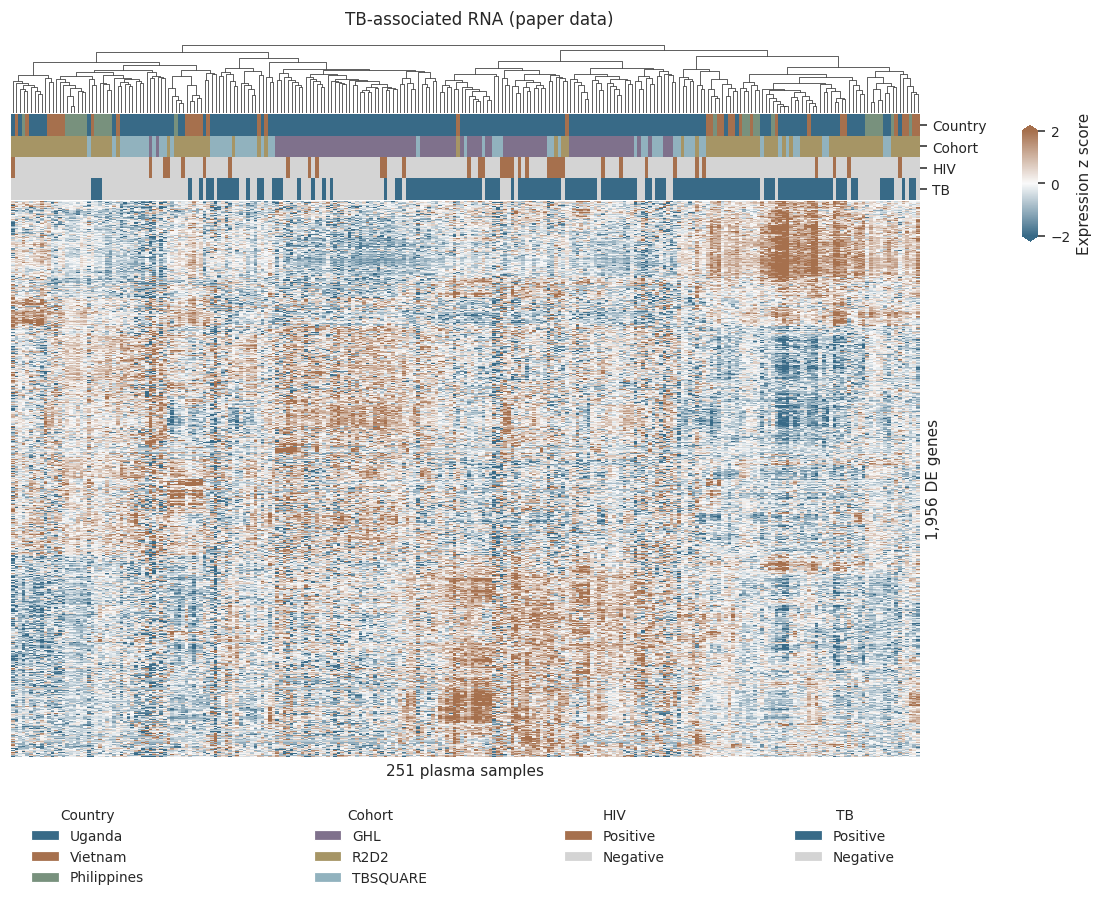

In [5]:
pooled_de = pd.read_csv(DATA / "deseq_results.tsv", sep="\t", index_col="gene_id")
heatmap_genes = pooled_de.index[
    (pooled_de["padj"] < 0.05) & (pooled_de["log2FoldChange"].abs() > 0)
]
pooled_log_means = reference_log_means(counts_all)
heatmap_expression = variance_stabilize(
    counts_all, pooled_log_means, reference["pooled_vst"]
)[heatmap_genes]
heatmap_values = (
    heatmap_expression.subtract(heatmap_expression.mean())
    .div(heatmap_expression.std(ddof=1))
    .T
)
assert np.isfinite(heatmap_values.to_numpy()).all()

annotation_colors = {
    "country": {"Uganda": "#386A87", "Vietnam": "#A6704D", "Philippines": "#78917D"},
    "cohort": {"GHL": "#7F718C", "R2D2": "#A69565", "TBSQUARE": "#91B2BE"},
    "hiv": {"Positive": "#A6704D", "Negative": "#D4D4D4"},
    "tb": {"positive": "#386A87", "negative": "#D4D4D4"},
}
column_colors = pd.DataFrame(
    {
        field: metadata_all[field].map(colors)
        for field, colors in annotation_colors.items()
    }
)
assert column_colors.notna().all().all()
heatmap = sns.clustermap(
    heatmap_values,
    method="complete",
    metric="correlation",
    cmap=LinearSegmentedColormap.from_list(
        "expression_z", ["#386A87", "#FAFAFA", "#A6704D"]
    ),
    center=0,
    vmin=-2,
    vmax=2,
    col_colors=column_colors,
    xticklabels=False,
    yticklabels=False,
    figsize=(9.5, 7),
    dendrogram_ratio=(0.04, 0.10),
    cbar_pos=(1.02, 0.72, 0.015, 0.15),
    cbar_kws={"label": "Expression z score", "ticks": [-2, 0, 2], "extend": "both"},
)
heatmap.ax_row_dendrogram.set_visible(False)
heatmap.ax_heatmap.collections[0].set_rasterized(True)
heatmap.ax_heatmap.set(
    xlabel="251 plasma samples", ylabel=f"{len(heatmap_genes):,} DE genes"
)
heatmap.fig.suptitle("TB-associated RNA (paper data)", y=1.02, fontsize=11)
annotation_labels = {"country": "Country", "cohort": "Cohort", "hiv": "HIV", "tb": "TB"}
heatmap.ax_col_colors.set_yticklabels(annotation_labels.values(), rotation=0)
for position, (field, colors) in zip(
    [0.06, 0.33, 0.57, 0.79], annotation_colors.items()
):
    heatmap.fig.legend(
        handles=[
            Patch(facecolor=color, label=label.capitalize() if field == "tb" else label)
            for label, color in colors.items()
        ],
        title=annotation_labels[field],
        loc="upper left",
        bbox_to_anchor=(position, 0),
        frameon=False,
        title_fontsize=9,
    )
save_figure(heatmap.fig, "figure_1C_de_heatmap")
plt.show()

### Figure 1D: pathways

Read the supplied Ingenuity Pathway Analysis (IPA) results. Apply the repository's
display filters and plot the absolute activation score. Color shows its sign.
This redraw does not rerun the IPA software.

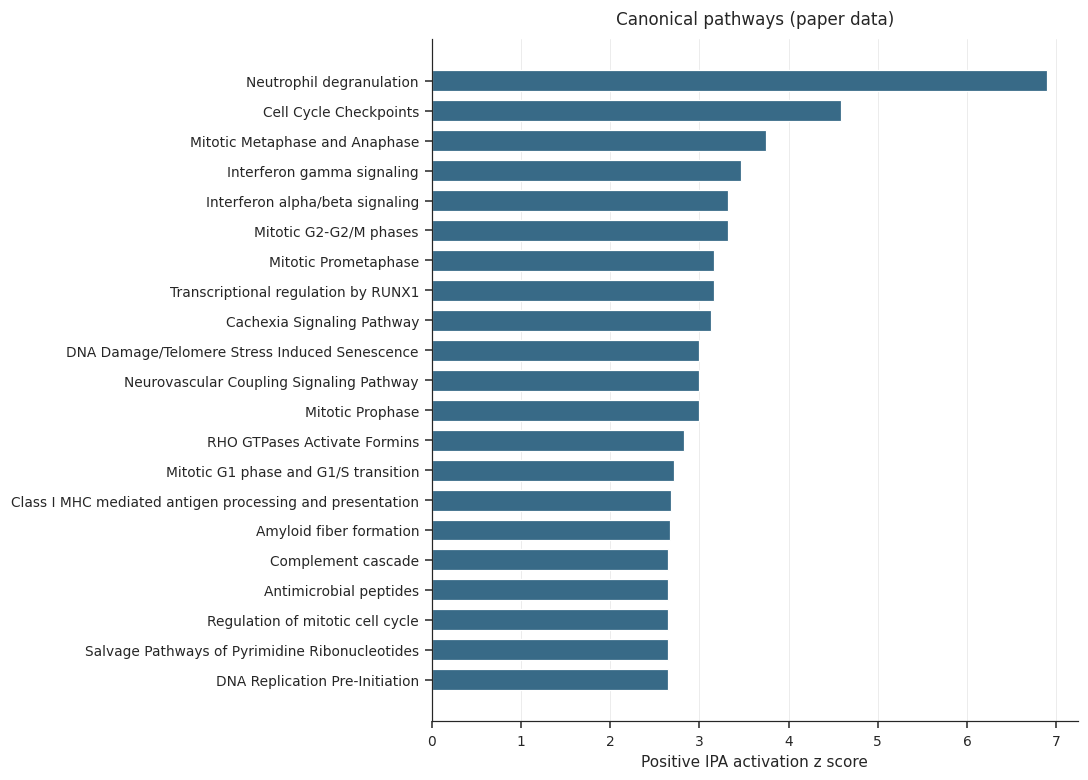

In [6]:
pathways = pd.read_csv(DATA / "ipa_output.txt", sep="\t")
pathways.columns = pathways.columns.str.strip()
for column in ["-log(p-value)", "z-score"]:
    pathways[column] = pd.to_numeric(pathways[column], errors="coerce")
pathways["molecule_count"] = pathways["Molecules"].str.count(",") + 1
selected_pathways = pathways.loc[
    (pathways["-log(p-value)"].abs() > 1)
    & (pathways["z-score"].abs() > 2.55)
    & (pathways["molecule_count"] > 6)
].copy()
selected_pathways["absolute_z"] = selected_pathways["z-score"].abs()
selected_pathways = selected_pathways.sort_values("absolute_z")

figure, axis = plt.subplots(figsize=(10, 7.2))
axis.barh(
    selected_pathways["Ingenuity Canonical Pathways"],
    selected_pathways["absolute_z"],
    color=np.where(selected_pathways["z-score"] > 0, NEW_COLOR, "#A6704D"),
    height=0.7,
)
axis.set(
    xlabel="Absolute IPA activation z score",
    title="Canonical pathways (paper data)",
)
if (selected_pathways["z-score"] > 0).all():
    axis.set_xlabel("Positive IPA activation z score")
else:
    axis.legend(
        handles=[
            Patch(color=NEW_COLOR, label="Positive"),
            Patch(color="#A6704D", label="Negative"),
        ],
        frameon=False,
    )
axis.grid(axis="x", color="0.92", linewidth=0.6)
axis.set_axisbelow(True)
figure.tight_layout()
save_figure(figure, "figure_1D_ipa_pathways")
plt.show()
selected_pathways.to_csv(OUTPUT / "figure_1D_ipa_pathways.csv", index=False)

### Define one AUC plot for all comparisons

Sort each table by test AUC. Label the paper replica directly and mark it with
dark marks and a shaded row; new fits use blue marks. Homogeneous panels
identify their source in the title. Open marks indicate training, filled
circles/diamonds indicate test, and filled triangles indicate validation. Keep the same full AUC axis in every panel. These are point
estimates; the ranking alone does not establish a performance difference.

In [7]:
DISPLAY_NAMES = {
    "EXTRATREES": "ExtraTrees",
    "GLMNETLasso": "Lasso",
    "GLMNETRidge": "Ridge",
    "DummyClassifier": "Dummy",
    "LogisticRegression": "Logistic (L2; Lazy)",
    "RidgeClassifier": "Ridge classifier (Lazy)",
    "LinearSVC": "Linear SVM (Lazy)",
    "GaussianNB": "Gaussian NB (Lazy)",
    "KNeighborsClassifier": "KNN (Lazy)",
    "SVC": "RBF SVM (Lazy)",
    "RandomForestClassifier": "Random forest (Lazy)",
    "ExtraTreesClassifier": "ExtraTrees (Lazy)",
    "XGBClassifier": "XGBoost",
    "MLPClassifier": "Neural network (8 units)",
    "GFS": "GFS",
    "Logistic GLM: no penalty": "Logistic: no penalty",
    "Logistic GLM: L2 (Ridge)": "Logistic: L2 (Ridge)",
    "Logistic GLM: L1 (Lasso)": "Logistic: L1 (Lasso)",
    "Logistic GLM: elastic net": "Logistic: elastic net",
}


SPLIT_MARKERS = {"train": "o", "test": "o", "val": "^"}


def draw_auc_panel(axis, results, title, model_order=None):
    ordered = results.sort_values(["test_auc", "model"], ascending=[False, True])
    if model_order is not None:
        ordered = results.set_index("model").loc[model_order].reset_index()
    ordered = ordered.reset_index(drop=True)
    labels = []
    for position, row in ordered.iterrows():
        is_paper = row.source.startswith("Paper")
        color = PAPER_COLOR if is_paper else NEW_COLOR
        name = DISPLAY_NAMES.get(row.model, row.model)
        labels.append(
            f"{name} (paper replica)" if row.source == "Paper replica" else name
        )
        if row.source == "Paper replica":
            axis.axhspan(position - 0.44, position + 0.44, color="0.94", zorder=0)
        for split, offset in zip(split_labels, [-0.24, 0, 0.24]):
            marker = "D" if is_paper and split != "val" else SPLIT_MARKERS[split]
            axis.scatter(
                row[f"{split}_auc"],
                position + offset,
                marker=marker,
                s=30,
                linewidths=1,
                facecolors="white" if split == "train" else color,
                edgecolors=color,
                zorder=3,
            )
    axis.axvline(0.5, color="0.6", linestyle="--", linewidth=1)
    axis.set(
        yticks=range(len(ordered)),
        yticklabels=labels,
        xlim=(0, 1.03),
        ylim=(len(ordered) - 0.4, -0.6),
        xlabel="ROC AUC",
        title=title,
    )
    axis.grid(axis="x", color="0.92", linewidth=0.6)
    axis.set_axisbelow(True)
    axis.tick_params(axis="y", length=0)
    return ordered


def add_auc_legend(figure):
    handles = [
        Line2D(
            [],
            [],
            marker=SPLIT_MARKERS[split],
            color="0.3",
            linestyle="",
            markerfacecolor="white" if split == "train" else "0.3",
            markersize=5,
            label=f"{SPLIT_NAMES[split]} (n={len(labels)})",
        )
        for split, labels in split_labels.items()
    ]
    figure.legend(
        handles=handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.01),
        ncol=3,
        frameon=False,
    )


def display_auc_table(results, extra_columns=()):
    """Use one table format for all training/test/validation comparisons."""
    columns = ["source", "model", *auc_columns, *extra_columns]
    table = (
        results[columns]
        .assign(model=results.model.replace(DISPLAY_NAMES))
        .rename(columns={
            "source": "Source", "model": "Model", "method": "Selection", "search": "Search",
            "n_features": "Gene count", "selected_genes": "Selected genes",
            **{f"{split}_auc": f"{label} AUC" for split, label in SPLIT_NAMES.items()},
        })
        .round(4)
    )
    display(
        table.style.format(precision=4)
        .highlight_max(subset=[f"{label} AUC" for label in SPLIT_NAMES.values()],
                       props="font-weight: bold; background-color: #e8f1f7;")
        .set_properties(subset=["Selected genes"] if "Selected genes" in table else [],
                        **{"max-width": "300px", "white-space": "normal"})
        .hide(axis="index")
    )


### Figure 1F: reported model scores

Read the published training, test, and validation AUC values from `ml_auc.txt`. Redraw all
reported rows. These are stored results, not new fits. GFS used six final genes;
the other model searches began with the reported 113-gene candidate pool.

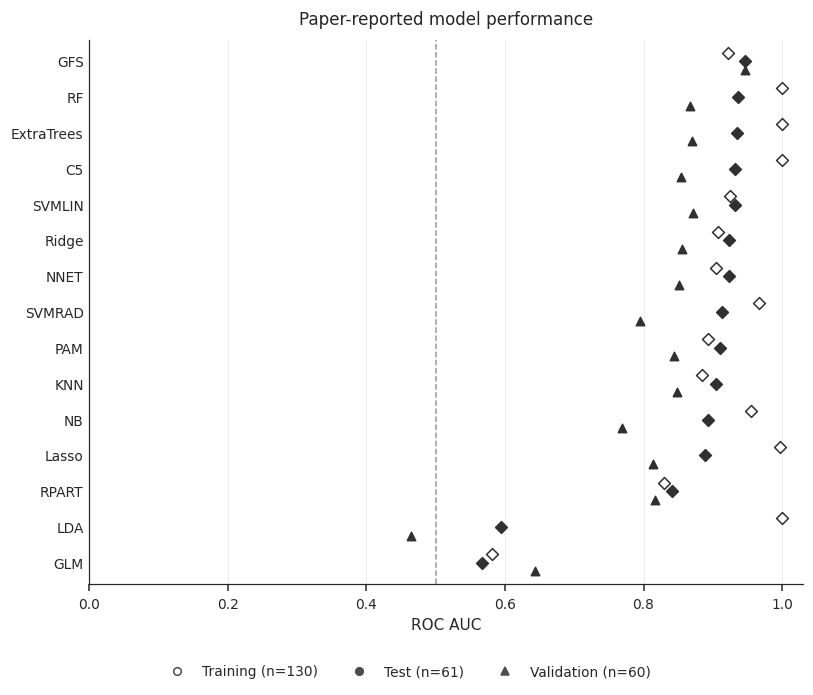

In [8]:
published_auc = pd.read_csv(DATA / "ml_auc.txt", sep="\t")
published_auc = published_auc.pivot(index="model", columns="method", values="auc")
published_auc = published_auc.rename(columns={split: f"{split}_auc" for split in split_labels})
published_auc = published_auc.reset_index().assign(source="Paper reported")
figure, axis = plt.subplots(figsize=(7.5, 6.4))
draw_auc_panel(axis, published_auc, "Paper-reported model performance")
add_auc_legend(figure)
figure.tight_layout(rect=(0, 0.07, 1, 1))
save_figure(figure, "figure_1F_reported")
plt.show()

## 4. Reproduce the six-gene paper scores

Each participant contributes **one expression value per gene**: GBP5, BNIP3L,
KLF6, DYSF, LASP1, and PCBP1. Thus, the training input has **130 rows and six
columns**; test and validation have **61 and 60 rows**, respectively, with the
same six columns. TB labels are separate
from these six input columns. Coefficients are learned model weights, not inputs.

The preparation order is:

`Gene counts → size-factor normalization → VST → select six gene columns`

The R exporter reads `Files_For_Manuscript/counts.{train,test,val}.tsv`, applies
the paper's independent VST in each split, and writes the six columns to
`Files_For_Manuscript/gene_cutoff_reference/paper_model/paper_features.tsv`.
Normalization uses the full count matrices before the six columns are selected.
The classifiers themselves receive only those six columns.

Load these already transformed values below. Calculate the paper probabilities
in Python and check them against exported R predictions and reported AUCs.
The paper GLM uses the VST values directly. Our four logistic controls add
training-based standardization before fitting; the training mean and SD are
also used for test and validation samples. The later DE-versus-all-genes experiment uses a
different VST protocol fitted on training samples.

See the [R exporter](../Files_For_Manuscript/gene_cutoff_reference/paper_model/export_reference.R)
and [DESeq2 VST documentation](https://bioconductor.org/packages/release/bioc/manuals/DESeq2/man/DESeq2.pdf#page=58).

This cell scores the reconstructed R model. It does not rerun GFS gene selection.
The reconstruction uses the paper's no-intercept formula and GLM controls.
Its provenance and R exporter are in `gene_cutoff_reference/paper_model/`.

In [9]:
paper_model = json.loads((PAPER_REFERENCE / "model.json").read_text())
check_hashes(paper_model["input_sha256"])
check_hashes(paper_model["output_sha256"])
paper_features = pd.read_csv(
    PAPER_REFERENCE / "paper_features.tsv", sep="\t", index_col="sample_id"
)
r_predictions = pd.read_csv(
    PAPER_REFERENCE / "r_predictions.csv", index_col="sample_id"
)
paper_genes = paper_model["genes"]
paper_coefficients = (
    pd.Series(paper_model["coefficients"]).reindex(paper_genes).to_numpy()
)
assert len(paper_genes) == 6 and paper_model["intercept"] == 0
assert paper_model["penalty"] == "none"
paper_inputs = {
    split: paper_features.loc[metadata.index, paper_genes]
    for split, metadata in split_metadata.items()
}
paper_train, paper_test = paper_inputs["train"], paper_inputs["test"]
assert paper_train.shape == (130, 6) and paper_test.shape == (61, 6)
paper_scores = {}
for split, features in paper_inputs.items():
    labels = split_labels[split]
    assert paper_features.loc[features.index, "split"].eq(split).all()
    np.testing.assert_array_equal(
        paper_features.loc[features.index, "tb_binary"], labels
    )
    paper_scores[split] = expit(features.to_numpy() @ paper_coefficients)
    np.testing.assert_allclose(
        paper_scores[split],
        r_predictions.loc[features.index, "probability"],
        atol=1e-12,
    )
paper_result = pd.DataFrame(
    [
        {
            "source": "Paper replica",
            "model": "GFS",
            "n_features": 6,
            **{
                f"{split}_auc": roc_auc_score(split_labels[split], scores)
                for split, scores in paper_scores.items()
            },
        }
    ]
)
auc_columns = [f"{split}_auc" for split in split_labels]
np.testing.assert_allclose(
    paper_result[auc_columns].iloc[0],
    published_auc.set_index("model")
    .loc["GFS", auc_columns]
    .astype(float),
    atol=1e-12,
)

### Define one score calculation for all classifiers

Calculate AUC from continuous scores, not binary class labels. Use log odds
for Gaussian naive Bayes to avoid probabilities rounded to zero or one.
Reuse these functions for the logistic controls and the LazyPredict screen,
scoring the same fitted model on training, test, and validation samples.

In [10]:
def positive_scores(model, features):
    """Return continuous scores for TB=1; avoid saturated NB probabilities."""
    assert np.array_equal(model.classes_, [0, 1])
    if hasattr(model, "decision_function"):
        return model.decision_function(features)
    if isinstance(model.steps[-1][1], GaussianNB):
        log_probabilities = model.predict_log_proba(features)
        return log_probabilities[:, 1] - log_probabilities[:, 0]
    return model.predict_proba(features)[:, 1]


def auc_result(name, model, features_by_split):
    scores = {
        split: positive_scores(model, features)
        for split, features in features_by_split.items()
    }
    row = {
        "source": "New",
        "model": name,
        "n_features": features_by_split["train"].shape[1],
        **{
            f"{split}_auc": roc_auc_score(split_labels[split], values)
            for split, values in scores.items()
        },
    }
    return row, scores

def save_prediction_scores(prediction_sets, filename):
    score_tables = []
    for feature_set, models in prediction_sets.items():
        for model_name, predictions in models.items():
            for split, metadata in split_metadata.items():
                score_tables.append(
                    pd.DataFrame(
                        {
                            "feature_set": feature_set,
                            "model": model_name,
                            "split": split,
                            "sample_id": metadata.index,
                            "tb_positive": split_labels[split],
                            "score": predictions[split],
                        }
                    )
                )
    pd.concat(score_tables, ignore_index=True).to_csv(
        OUTPUT / filename, index=False
    )


### Equations for the paper GLM and our four variants

These equations describe the **final six-gene logistic classifier** and our four
logistic controls. GFS is the paper's gene-selection procedure. Its final
classifier is a binomial GLM with a logit link.

**Symbols and inputs.** Participant $i$ has TB label $y_i=1$ for positive or
$y_i=0$ for negative. There are $n=130$ training participants and six genes,
indexed by $j$. Let $x_{ij}$ be the original VST value. Our new fits use
training-standardized values:

$$
z_{ij}=\frac{x_{ij}-\mu_{j,\mathrm{train}}}{s_{j,\mathrm{train}}}.
$$

Here $\mu$ and $s$ are the training mean and SD. The same values standardize
test samples. This is the current configuration with `fit_intercept=True`.

**Prediction rule shared by all five models.** The linear score $\eta_i$ is
converted to a probability $p_i$ with the logistic function:

$$
Y_i\mid\mathbf{x}_i\sim\operatorname{Bernoulli}(p_i),\qquad
\log\left(\frac{p_i}{1-p_i}\right)=\eta_i,\qquad
p_i=\frac{1}{1+\exp(-\eta_i)}.
$$

**Training loss.** The model estimates its parameters by minimizing an objective
$J$. Its prediction-error term is the **summed** negative log likelihood:

$$
\mathcal{L}=-\sum_{i=1}^{n}
\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right].
$$

Each model evaluates this loss using its own predicted probabilities. All logs
are natural. The equations below have no sample weights or class weights,
matching the current code.

**1. Paper model: no intercept, no penalty.** Fit six slopes $\gamma_j$ on the
original VST inputs. The intercept is fixed at zero:

$$
\eta_i^{\mathrm{paper}}=\sum_{j=1}^{6}\gamma_jx_{ij},
\qquad J_{\mathrm{paper}}=\mathcal{L}.
$$

The six terms correspond to GBP5, BNIP3L, KLF6, DYSF, LASP1, and PCBP1.
Our replica reconstructs this R specification; its full-precision fitted slopes
are stored in
[model.json](../Files_For_Manuscript/gene_cutoff_reference/paper_model/model.json).
They are reconstructed estimates, not an original serialized fitted model.

**2. New GLM: add a fitted intercept, without a penalty.** Fit a constant $b$
together with six slopes $\beta_j$ on the standardized inputs:

$$
\eta_i=b+\sum_{j=1}^{6}\beta_jz_{ij},
\qquad J_{\mathrm{none}}=\mathcal{L}.
$$

The different slope symbols distinguish VST units from standardized units.
All parameters are refitted jointly; we do not add a constant to the saved
paper predictions. With a free intercept, standardization changes the
unpenalized equation's coordinates without changing its representable predictions.

**3. L2 / ridge logistic regression.** Keep the new GLM prediction rule and add
a squared-coefficient penalty to its training objective:

$$
J_{\mathrm{L2}}=\mathcal{L}
+\frac{\lambda_2}{2}\sum_{j=1}^{6}\beta_j^2.
$$

Large coefficient magnitudes incur a larger penalty. This encourages smaller
weights; it does not guarantee better test predictions.

**4. L1 / lasso logistic regression.** Keep the same prediction rule and penalize
absolute coefficient magnitudes:

$$
J_{\mathrm{L1}}=\mathcal{L}
+\lambda_1\sum_{j=1}^{6}\lvert\beta_j\rvert.
$$

L1 can make some coefficients exactly zero, removing their contribution in
that fit. At our current setting, all six coefficients remain nonzero.

**5. Elastic-net logistic regression.** Keep the same prediction rule and
combine the L2 and L1 penalties:

$$
J_{\mathrm{EN}}=\mathcal{L}
+\lambda_{\mathrm{EN}}\left[
\frac{1-\rho}{2}\sum_{j=1}^{6}\beta_j^2
+\rho\sum_{j=1}^{6}\lvert\beta_j\rvert
\right].
$$

Here $\rho$ is `l1_ratio`. The current $\rho=0.5$ gives
$\lambda_{\mathrm{EN}}[0.25\sum_j\beta_j^2+0.5\sum_j\lvert\beta_j\rvert]$.
This mixture does not imply that both terms have equal numerical values.

**Connect the equations to the settings below.** For the summed loss used here,
each penalized model has $\lambda_k=1/C_k$. All three current `C` values are 1,
so $\lambda_2=\lambda_1=\lambda_{\mathrm{EN}}=1$. Smaller `C` means a larger
penalty. If the objective is written with **mean** loss $\mathcal{L}/n$, its
equivalent penalty multiplier is $1/(nC)$; at $n=130$ and $C=1$, this is
$1/130\approx0.00769$. These conventions give the same fitted optimum when
the entire objective is scaled consistently.

The intercept $b$ is **not penalized** by our SAGA solver. Regularization enters
the training objective; the probability rule remains logistic. Every model
uses additive gene terms. None adds a gene-pair term such as $z_{ij}z_{ik}$.

These L2 equations describe `LogisticRegression(penalty="l2")`. LazyPredict's
separate `RidgeClassifier` uses a squared-error objective.

### Set the logistic model parameters here

All four new models use the same six genes, samples, standardization rule,
intercept setting, solver, tolerance, and seed. Their penalty is the controlled
difference. Edit `settings` for shared fitting options and `regularization`
for each `C` value and the elastic-net mixture. The no-penalty fit ignores `C`.

SAGA supports all four penalty choices and leaves the intercept unpenalized.
The paper replica uses the reconstructed R no-intercept fit. The earlier
`liblinear` Ridge fit was replaced because that solver penalized its intercept.

These are **fixed settings**, not values chosen by cross-validation. Equal `C`
values do not imply equal shrinkage across penalty types. Use training
cross-validation to select future settings.

Sources: [original R model code](Figure_2.ipynb),
[reconstruction exporter](../Files_For_Manuscript/gene_cutoff_reference/paper_model/export_reference.R),
[scikit-learn objective and penalty definitions](https://scikit-learn.org/1.6/modules/linear_model.html#binary-case),
[solver differences](https://scikit-learn.org/1.6/modules/linear_model.html#solvers).


In [11]:
settings = {
    "fit_intercept": True,
    "solver": "saga",
    "tol": 1e-10,
    "max_iter": 2000,
    "random_state": SEED,
}
regularization = {
    "l2_C": 1.0,
    "l1_C": 1.0,
    "elastic_net_C": 1.0,
    "elastic_net_l1_ratio": 0.5,
}

controls = {
    "Logistic GLM: no penalty": LogisticRegression(penalty=None, **settings),
    "Logistic GLM: L2 (Ridge)": LogisticRegression(
        penalty="l2", C=regularization["l2_C"], **settings
    ),
    "Logistic GLM: L1 (Lasso)": LogisticRegression(
        penalty="l1", C=regularization["l1_C"], **settings
    ),
    "Logistic GLM: elastic net": LogisticRegression(
        penalty="elasticnet",
        C=regularization["elastic_net_C"],
        l1_ratio=regularization["elastic_net_l1_ratio"],
        **settings,
    ),
}

model_labels = {
    None: "No penalty",
    "l2": "L2 (Ridge)",
    "l1": "L1 (Lasso)",
    "elasticnet": "Elastic net",
}

### Fit the logistic controls and record their settings

Fit each scaler and classifier on training samples only. All four new models
use the same scaling rule. Stop if a solver fails to converge.

Center each gene when fitting an intercept. If you disable the intercept,
scale without centering to preserve the original zero point. Centering with
no intercept would impose a different constraint from the paper model.

The table reports training, test, and validation log loss and the number of
nonzero gene weights for the paper replica and four logistic controls.
Lower log loss means better probability predictions under this loss.
The AUC comparison appears once below, with all six-gene models.
Export coefficients in **standardized gene units**, not the paper's raw VST units.

In [12]:
control_rows, control_predictions, control_probabilities = [], {}, {}
coefficient_rows = []
with warnings.catch_warnings(), threadpool_limits(limits=1):
    warnings.simplefilter("error", ConvergenceWarning)
    for name, estimator in controls.items():
        scaler = StandardScaler(with_mean=settings["fit_intercept"])
        model = make_pipeline(scaler, estimator).fit(paper_train, y_train)
        row, scores = auc_result(name, model, paper_inputs)
        probabilities = {
            split: model.predict_proba(features)[:, 1]
            for split, features in paper_inputs.items()
        }
        weights = estimator.coef_.ravel()
        row.update(
            **{
                f"{split}_log_loss": log_loss(split_labels[split], values)
                for split, values in probabilities.items()
            },
            nonzero_weights=np.count_nonzero(weights),
            iterations=int(estimator.n_iter_.max()),
        )
        control_rows.append(row)
        control_predictions[name] = scores
        control_probabilities[name] = probabilities
        coefficient_rows.append(
            pd.Series(
                [estimator.intercept_[0], *weights],
                index=["Intercept", *paper_model["gene_names"]],
                name=name,
            )
        )
control_results = pd.DataFrame(control_rows)
control_results.to_csv(OUTPUT / "logistic_control_results.csv", index=False)
pd.DataFrame(coefficient_rows).rename_axis("model").to_csv(
    OUTPUT / "logistic_control_coefficients.csv"
)
(OUTPUT / "logistic_control_settings.json").write_text(
    json.dumps(
        {
            "settings": settings,
            "regularization": regularization,
            "standardization": {
                "with_mean": settings["fit_intercept"],
                "with_std": True,
            },
            "models": {name: model.get_params() for name, model in controls.items()},
        },
        indent=2,
    )
)
paper_metrics = paper_result.assign(
    **{
        f"{split}_log_loss": log_loss(split_labels[split], scores)
        for split, scores in paper_scores.items()
    },
    nonzero_weights=np.count_nonzero(paper_coefficients),
)
regularization_results = pd.concat([paper_metrics, control_results], ignore_index=True)
display(
    regularization_results[
        ["source", "model", *[f"{split}_log_loss" for split in split_labels],
         "nonzero_weights"]
    ].round(4)
)

,source,model,train_log_loss,test_log_loss,val_log_loss,nonzero_weights
0,Paper replica,GFS,0.3659,0.3345,0.3577,6
1,New,Logistic GLM: no penalty,0.3565,0.2920,0.3284,6
2,New,Logistic GLM: L2 (Ridge),0.3586,0.3041,0.3438,6
3,New,Logistic GLM: L1 (Lasso),0.3599,0.3028,0.3623,6
4,New,Logistic GLM: elastic net,0.3590,0.3032,0.3515,6


### Compare gene coefficients across all five fitted models

**A gene coefficient is a learned weight in the prediction equation.** Raw
counts already measure RNA abundance. We normalize and transform them for
modeling. Each participant has six input values, one per gene; the coefficient
is estimated from these values and known TB status. It describes how that gene changes the model's prediction **while
the other five genes are held fixed**.

**How is it estimated?** Logistic regression fits all six weights together using
the 130 training participants. It minimizes log loss, which penalizes predicted
probabilities that disagree with the observed TB labels. L2 also penalizes squared
weights; L1 penalizes absolute weights and can set them to zero; elastic net mixes
the two. The 61 test participants do not enter these coefficient fits. The paper
replica uses the reproduced R fit; the other four models use the Python fits above.

**What does the number mean?** Each gene is put on a common scale using its
training mean and standard deviation (SD):

$$
z_j=\frac{x_j-\mu_{j,\mathrm{train}}}{s_{j,\mathrm{train}}},
\qquad
\log\!\left(\frac{p}{1-p}\right)=b+\sum_{j=1}^{6}\beta_jz_j.
$$

Here $x_j$ is VST expression, $p$ is predicted TB probability, $b$ is the intercept,
and $\beta_j$ is the gene coefficient. The log is natural. Increasing expression
by **one training SD** changes predicted log odds by $\beta_j$, or multiplies
predicted odds by $e^{\beta_j}$.

| Coefficient | Meaning for higher expression, with the other genes fixed |
|---|---|
| Positive | Higher predicted TB odds. |
| Zero | No contribution from that gene in this fitted model. |
| Negative | Lower predicted TB odds. |

A larger absolute value means a larger change in log odds for the same SD
increase. Odds are $p/(1-p)$; an odds multiplier is **not** a probability
multiplier. The contribution for a particular participant is $\beta_jz_j$,
so the coefficient alone is not that participant's contribution.

**Read the figure across each gene row.** Each point is one coefficient; every
panel uses the same numerical scale and a dashed line at zero. The paper slopes
are converted from VST units by multiplying by the same training SDs. This
conversion preserves its predictions. The paper has no fitted intercept; the
four new fits currently include one. Compare the new penalized fits with the
new unpenalized fit to isolate the penalty's effect.

These are point estimates without coefficient confidence intervals. Correlated
genes can redistribute weights between them. A coefficient is not an expression
fold change, a p-value, or a percentage of importance; it does not establish a
causal gene effect. These models contain no gene-by-gene interaction terms.

Methods: [logistic regression](https://scikit-learn.org/1.6/modules/linear_model.html#logistic-regression)
and [training-data standardization](https://scikit-learn.org/1.6/modules/generated/sklearn.preprocessing.StandardScaler.html).

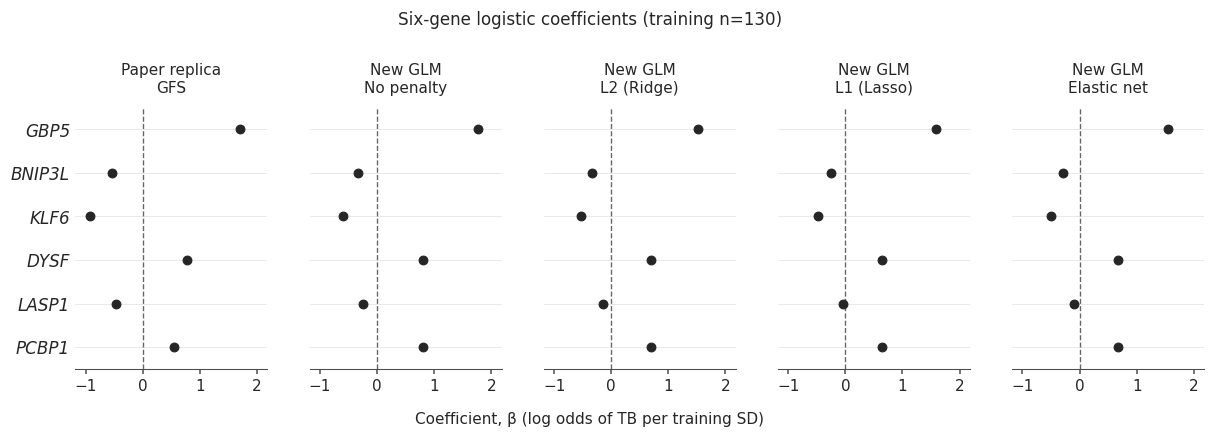

**Worked example — GBP5:** in the L2 model, β = **+1.52**. Increasing GBP5 by one training SD (1.05 VST units), with the other five genes fixed, multiplies predicted TB odds by **4.59**. For an illustrative starting probability of 0.20, that gives 0.53; this is not a 4.59-fold increase in probability.

**Reading the penalty comparison:** LASP1 changes from β = -0.249 without a penalty to -0.040 under L1. Its fitted contribution per SD is closer to zero. L1 retains 6 of the 6 gene weights at the current setting. The next figure shows how these weights change as penalty strength varies.

In [13]:
gene_names = paper_model["gene_names"]
coefficient_scaler = StandardScaler(with_mean=settings["fit_intercept"]).fit(
    paper_train
)
paper_scaled_weights = paper_coefficients * coefficient_scaler.scale_
training_center = (
    coefficient_scaler.mean_
    if coefficient_scaler.with_mean
    else np.zeros(len(paper_genes))
)
# This is a coordinate offset, not a newly fitted intercept.
paper_coordinate_offset = (
    paper_model["intercept"] + training_center @ paper_coefficients
)
for split, features in paper_inputs.items():
    equivalent_scores = expit(
        coefficient_scaler.transform(features) @ paper_scaled_weights
        + paper_coordinate_offset
    )
    np.testing.assert_allclose(
        equivalent_scores, paper_scores[split], rtol=0, atol=1e-12
    )

coefficient_vectors = {
    "Paper replica: GFS": paper_scaled_weights,
    **{name: estimator.coef_.ravel() for name, estimator in controls.items()},
}
coefficient_comparison = pd.DataFrame.from_dict(
    coefficient_vectors,
    orient="index",
    columns=gene_names,
).rename_axis("model")
coefficient_comparison.to_csv(OUTPUT / "logistic_five_model_coefficients.csv")
pd.DataFrame(
    {
        "gene_id": paper_genes,
        "gene": gene_names,
        "training_center": training_center,
        "training_sd": coefficient_scaler.scale_,
    }
).to_csv(OUTPUT / "logistic_coefficient_scaling.csv", index=False)

# Aligned point estimates: position encodes sign and magnitude directly.
coefficient_titles = ["Paper replica\nGFS"] + [
    f"New GLM\n{model_labels[model.penalty]}" for model in controls.values()
]
coefficient_values = coefficient_comparison.to_numpy()
coefficient_min = min(-1, np.floor(coefficient_values.min()))
coefficient_max = max(1, np.ceil(coefficient_values.max()))
gene_positions = np.arange(len(gene_names))

with plt.rc_context({"font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10}):
    figure, axes = plt.subplots(
        1, len(coefficient_comparison), figsize=(11.4, 4.4), sharex=True, sharey=True
    )
    for axis, (_, weights), title in zip(
        axes, coefficient_comparison.iterrows(), coefficient_titles
    ):
        axis.grid(False)
        axis.set_axisbelow(True)
        axis.grid(axis="y", color="0.91", linewidth=0.6)
        axis.axvline(0, color="0.4", linestyle="--", linewidth=0.9, zorder=1)
        axis.scatter(weights, gene_positions, s=32, color="0.15", zorder=3)
        axis.set(
            title=title,
            xlim=(coefficient_min - 0.18, coefficient_max + 0.18),
            ylim=(len(gene_names) - 0.5, -0.5),
        )
        axis.set_yticks(gene_positions, labels=gene_names, fontstyle="italic")
        axis.xaxis.set_major_locator(MaxNLocator(nbins=4, integer=True))
        axis.tick_params(axis="x", labelsize=10, length=3, color="0.3")
        axis.tick_params(axis="y", length=0, labelsize=11)
        axis.spines[["top", "right", "left"]].set_visible(False)
        axis.spines["bottom"].set(color="0.3", linewidth=0.7)
    figure.suptitle(
        f"Six-gene logistic coefficients (training n={len(y_train)})",
        fontsize=11,
        y=0.98,
    )
    figure.supxlabel(
        "Coefficient, β (log odds of TB per training SD)",
        fontsize=10,
        y=0.12,
    )
    figure.subplots_adjust(left=0.09, right=0.99, bottom=0.24, top=0.78, wspace=0.22)
    save_figure(figure, "logistic_five_model_coefficients")
    plt.show()

# Translate fitted coefficients into an example on the odds scale.
l2_name = next(name for name, model in controls.items() if model.penalty == "l2")
l1_name = next(name for name, model in controls.items() if model.penalty == "l1")
no_penalty_name = next(
    name for name, model in controls.items() if model.penalty is None
)
gbp5_weight = coefficient_comparison.loc[l2_name, "GBP5"]
gbp5_sd = coefficient_scaler.scale_[gene_names.index("GBP5")]
gbp5_odds_multiplier = np.exp(gbp5_weight)
illustrative_probability = expit(np.log(0.20 / 0.80) + gbp5_weight)
lasp1_unpenalized = coefficient_comparison.loc[no_penalty_name, "LASP1"]
lasp1_l1 = coefficient_comparison.loc[l1_name, "LASP1"]
display(
    Markdown(
        f"**Worked example — GBP5:** in the L2 model, β = **{gbp5_weight:+.2f}**. "
        f"Increasing GBP5 by one training SD ({gbp5_sd:.2f} VST units), with the other "
        f"five genes fixed, multiplies predicted TB odds by **{gbp5_odds_multiplier:.2f}**. "
        f"For an illustrative starting probability of 0.20, that gives "
        f"{illustrative_probability:.2f}; this is not a "
        f"{gbp5_odds_multiplier:.2f}-fold increase in probability.\n\n"
        f"**Reading the penalty comparison:** LASP1 changes from "
        f"β = {lasp1_unpenalized:+.3f} without a penalty to {lasp1_l1:+.3f} under L1. "
        f"Its fitted contribution per SD is closer to zero. "
        f"L1 retains {np.count_nonzero(coefficient_comparison.loc[l1_name])} of the "
        f"{len(gene_names)} gene weights at the current setting. "
        f"The next figure shows how these weights change as penalty strength varies."
    )
)

### Fit coefficient regularization paths on training samples

Use coefficient paths to show how penalties change the six gene weights.
Only L2, L1, and elastic net have a penalty strength to vary. The paper model
and new unpenalized GLM have no such path; compare their fixed weights above.
This follows the display used by [Friedman, Hastie, and Tibshirani (2010),
Figure 1](https://www.jstatsoft.org/article/view/v033i01), adapted here to
our logistic models. See also the [logistic regression path example](https://scikit-learn.org/1.6/auto_examples/linear_model/plot_logistic_path.html).

Fit copies of the three penalized models across a logarithmic grid of `C`.
Use the same 130 training participants, six genes, training scaler, and shared
settings. Keep the configured elastic-net mixture fixed. Do not use test data
to fit these paths or select a penalty. The original fixed models stay unchanged.

`C` is inverse penalty strength: smaller values impose a stronger penalty.
We label the axis with `C` because the numerical value of lambda depends on
whether the fitting objective uses summed or mean log loss.

In [14]:
path_settings = {"C_min": 1e-3, "C_max": 1e3, "points": 61}
path_models = {
    name: model for name, model in controls.items() if model.penalty is not None
}
path_C_values = np.unique(
    np.append(
        np.geomspace(
            path_settings["C_min"], path_settings["C_max"], path_settings["points"]
        ),
        [model.C for model in path_models.values()],
    )
)
path_scaler = StandardScaler(with_mean=settings["fit_intercept"])
path_training = path_scaler.fit_transform(paper_train)
gene_names = paper_model["gene_names"]
path_rows = []
with warnings.catch_warnings(), threadpool_limits(limits=1):
    warnings.simplefilter("error", ConvergenceWarning)
    for name, template in path_models.items():
        for penalty_C in path_C_values:
            fitted = clone(template).set_params(C=penalty_C).fit(path_training, y_train)
            row = {
                "model": name,
                "penalty": fitted.penalty,
                "C": penalty_C,
                "l1_ratio": fitted.l1_ratio,
                "intercept": fitted.intercept_[0],
                "nonzero_genes": np.count_nonzero(fitted.coef_),
                "iterations": int(fitted.n_iter_.max()),
            }
            row.update(dict(zip(gene_names, fitted.coef_.ravel())))
            path_rows.append(row)
path_results = pd.DataFrame(path_rows)
path_results.to_csv(OUTPUT / "logistic_regularization_paths.csv", index=False)
(OUTPUT / "logistic_path_settings.json").write_text(json.dumps(path_settings, indent=2))

55

### Plot how each penalty changes gene weights

Each line is one gene. Its coefficient is the change in log odds of TB per
training standard deviation, with the other genes held fixed. Positive and
negative weights indicate opposite directions within the fitted model.

Read left to right from stronger to weaker penalties. A coefficient of zero
removes that gene's contribution in that fit. Each vertical dotted line marks
the model's configured `C`; dots show its current six weights. Individual
weights need not change monotonically when genes are correlated.

These are **new training fits**, not paper results. The unpenalized intercept
is omitted from the paths. The paper's raw-VST coefficients are on a different
scale and are not overlaid. Weight changes do not establish causal importance
or gene interactions.

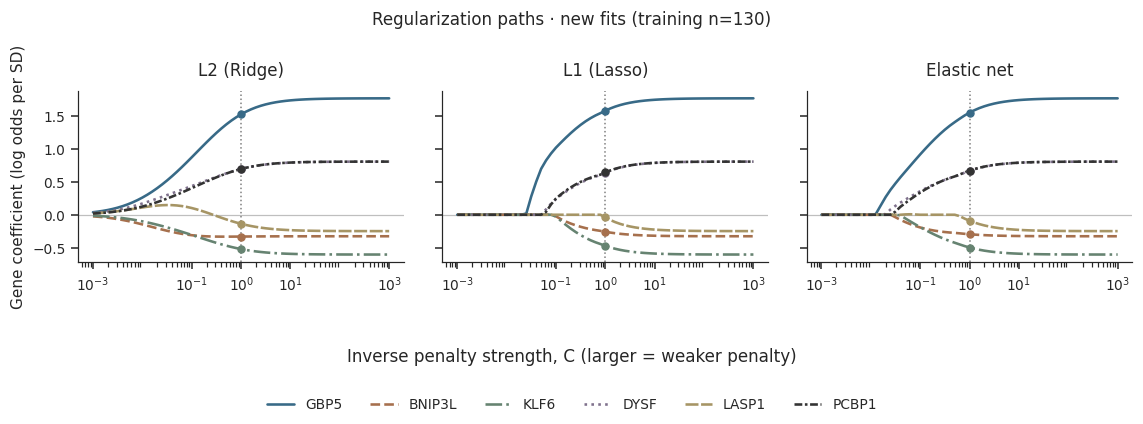

In [15]:
gene_colors = dict(
    zip(gene_names, ["#386A87", "#A6704D", "#668371", "#7F718C", "#A69565", "#333333"])
)
gene_styles = dict(
    zip(gene_names, ["-", "--", "-.", ":", (0, (5, 1)), (0, (3, 1, 1, 1))])
)
figure, axes = plt.subplots(1, 3, figsize=(10.5, 3.8), sharex=True, sharey=True)
for axis, (name, template) in zip(axes, path_models.items()):
    path_table = path_results.loc[path_results.model == name].sort_values("C")
    for gene, weight in zip(gene_names, template.coef_.ravel()):
        axis.plot(
            path_table.C,
            path_table[gene],
            color=gene_colors[gene],
            linestyle=gene_styles[gene],
            linewidth=1.7,
            label=gene,
        )
        axis.scatter(template.C, weight, color=gene_colors[gene], s=22, zorder=3)
    axis.axvline(template.C, color="0.5", linestyle=":", linewidth=1)
    axis.axhline(0, color="0.75", linewidth=0.8, zorder=0)
    axis.set(xscale="log", title=model_labels[template.penalty])
    axis.set_xticks([1e-3, 1e-1, 1, 1e1, 1e3])
    axis.yaxis.set_major_locator(MaxNLocator(nbins=6))
    axis.grid(False)
    axis.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Gene coefficient (log odds per SD)", fontsize=10)
figure.supxlabel(
    "Inverse penalty strength, C (larger = weaker penalty)", fontsize=11, y=0.13
)
figure.suptitle(
    f"Regularization paths · new fits (training n={len(y_train)})", fontsize=11
)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(
    handles,
    labels,
    loc="lower center",
    ncol=len(gene_names),
    frameon=False,
    fontsize=9,
)
figure.tight_layout(rect=(0, 0.18, 1, 0.98), w_pad=2)
save_figure(figure, "logistic_regularization_paths")
plt.show()

### Calculate ROC curves for all splits and test-set uncertainty

ROC curves show sensitivity against the false-positive rate as the decision
threshold changes. AUC summarizes ranking across thresholds. This is the
standard classifier comparison described by [Fawcett (2006)](https://doi.org/10.1016/j.patrec.2005.10.010).

Use the original fixed models, not models selected from the coefficient paths.
Compute curves from continuous scores for training (130), test (61), and
validation (60) participants. Do not smooth the empirical curves.

Keep the paired bootstrap restricted to the test set (34 positive, 27 negative).
Resample within each
TB class and use the same participant indices for all five fitted models.
Report percentile intervals for AUC and paired metric changes. These exploratory
intervals condition on the fitted models and class counts. They exclude training
and model-selection uncertainty, site clustering, and multiplicity correction.
This test set has already been examined during model exploration.

In [16]:
BOOTSTRAP_SAMPLES = 2000
CONFIDENCE_LEVEL = 0.95
paper_name = "Paper replica: no intercept, no penalty"
control_names = {model.penalty: name for name, model in controls.items()}
unpenalized_name = control_names[None]
all_probabilities = {paper_name: paper_scores, **control_probabilities}
probability_sets = {name: values["test"] for name, values in all_probabilities.items()}
model_names = list(probability_sets)


def test_metrics(sample_indices):
    """Measure all fixed models on the same test participants."""
    labels = y_test[sample_indices]
    return np.array(
        [
            [
                roc_auc_score(labels, probabilities[sample_indices]),
                log_loss(labels, probabilities[sample_indices]),
            ]
            for probabilities in probability_sets.values()
        ]
    )


observed_metrics = test_metrics(np.arange(len(y_test)))
class_indices = [np.flatnonzero(y_test == status) for status in [0, 1]]
random = np.random.default_rng(SEED)
bootstrap_metrics = []
for _ in range(BOOTSTRAP_SAMPLES):
    sample_indices = np.concatenate(
        [
            random.choice(indices, size=len(indices), replace=True)
            for indices in class_indices
        ]
    )
    bootstrap_metrics.append(test_metrics(sample_indices))
bootstrap_metrics = np.asarray(bootstrap_metrics)
tail = (1 - CONFIDENCE_LEVEL) / 2
metric_lower, metric_upper = np.quantile(bootstrap_metrics, [tail, 1 - tail], axis=0)
roc_results = pd.DataFrame(
    {
        "model": model_names,
        "test_auc": observed_metrics[:, 0],
        "auc_lower": metric_lower[:, 0],
        "auc_upper": metric_upper[:, 0],
        "test_log_loss": observed_metrics[:, 1],
        "bootstrap_samples": BOOTSTRAP_SAMPLES,
        "confidence_level": CONFIDENCE_LEVEL,
        "seed": SEED,
    }
)
roc_results.to_csv(OUTPUT / "logistic_test_roc_results.csv", index=False)

comparisons = {
    "No penalty vs paper": (paper_name, unpenalized_name),
    "L2 vs no penalty": (unpenalized_name, control_names["l2"]),
    "L1 vs no penalty": (unpenalized_name, control_names["l1"]),
    "Elastic net vs no penalty": (unpenalized_name, control_names["elasticnet"]),
}
comparison_rows = []
for label, (baseline, candidate) in comparisons.items():
    baseline_index, candidate_index = (
        model_names.index(baseline),
        model_names.index(candidate),
    )
    change = (observed_metrics[candidate_index] - observed_metrics[baseline_index]) * [
        1,
        -1,
    ]
    resampled_changes = (
        bootstrap_metrics[:, candidate_index] - bootstrap_metrics[:, baseline_index]
    ) * [1, -1]
    lower, upper = np.quantile(resampled_changes, [tail, 1 - tail], axis=0)
    comparison_rows.append(
        {
            "comparison": label,
            "baseline": baseline,
            "candidate": candidate,
            "auc_change": change[0],
            "auc_lower": lower[0],
            "auc_upper": upper[0],
            "log_loss_reduction": change[1],
            "loss_lower": lower[1],
            "loss_upper": upper[1],
            "bootstrap_samples": BOOTSTRAP_SAMPLES,
            "confidence_level": CONFIDENCE_LEVEL,
            "seed": SEED,
        }
    )
paired_results = pd.DataFrame(comparison_rows)
paired_results.to_csv(OUTPUT / "logistic_paired_comparisons.csv", index=False)
roc_tables, probability_tables = [], []
for name, predictions in all_probabilities.items():
    for split, probabilities in predictions.items():
        labels = split_labels[split]
        false_positive_rate, sensitivity, thresholds = roc_curve(
            labels, probabilities, drop_intermediate=False
        )
        roc_tables.append(
            pd.DataFrame(
                {
                    "model": name,
                    "split": split,
                    "false_positive_rate": false_positive_rate,
                    "sensitivity": sensitivity,
                    "threshold": thresholds,
                }
            )
        )
        probability_tables.append(
            pd.DataFrame(
                {
                    "model": name,
                    "split": split,
                    "sample_id": split_metadata[split].index,
                    "tb_positive": labels,
                    "probability": probabilities,
                }
            )
        )
roc_points = pd.concat(roc_tables, ignore_index=True)
roc_points.to_csv(OUTPUT / "logistic_roc_points.csv", index=False)
roc_points.loc[roc_points.split.eq("test")].drop(columns="split").to_csv(
    OUTPUT / "logistic_test_roc_points.csv", index=False
)
probability_table = pd.concat(probability_tables, ignore_index=True)
probability_table.to_csv(OUTPUT / "logistic_probabilities.csv", index=False)
# Preserve the test-only input used by gene_cutoff_interpretation.ipynb.
probability_table.loc[probability_table.split.eq("test")].drop(columns="split").to_csv(
    OUTPUT / "logistic_control_probabilities.csv", index=False
)
display(roc_results[["model", "test_auc", "auc_lower", "auc_upper"]].round(4))

,model,test_auc,auc_lower,auc_upper
0,"Paper replica: no intercept, no penalty",0.9466,0.8834,0.9946
1,Logistic GLM: no penalty,0.9597,0.9020,0.9989
2,Logistic GLM: L2 (Ridge),0.9608,0.9063,0.9978
3,Logistic GLM: L1 (Lasso),0.9597,0.9041,0.9967
4,Logistic GLM: elastic net,0.9586,0.9041,0.9967


### Compare ROC curves across training, test, and validation

Columns show the three datasets; rows show the four fixed logistic controls.
Each panel compares the **new model** (solid blue) with the **paper replica**
(dashed dark), scored on the same participants. Legends report each AUC.
All axes run from zero to one. The uncertainty table above applies to test only.

Curves closer to the upper-left corner have higher sensitivity at a given
false-positive rate. Similar AUCs do not establish equivalence or superiority.
These curves do not assess calibration or establish gene interactions.
No test or validation threshold or penalty is selected.


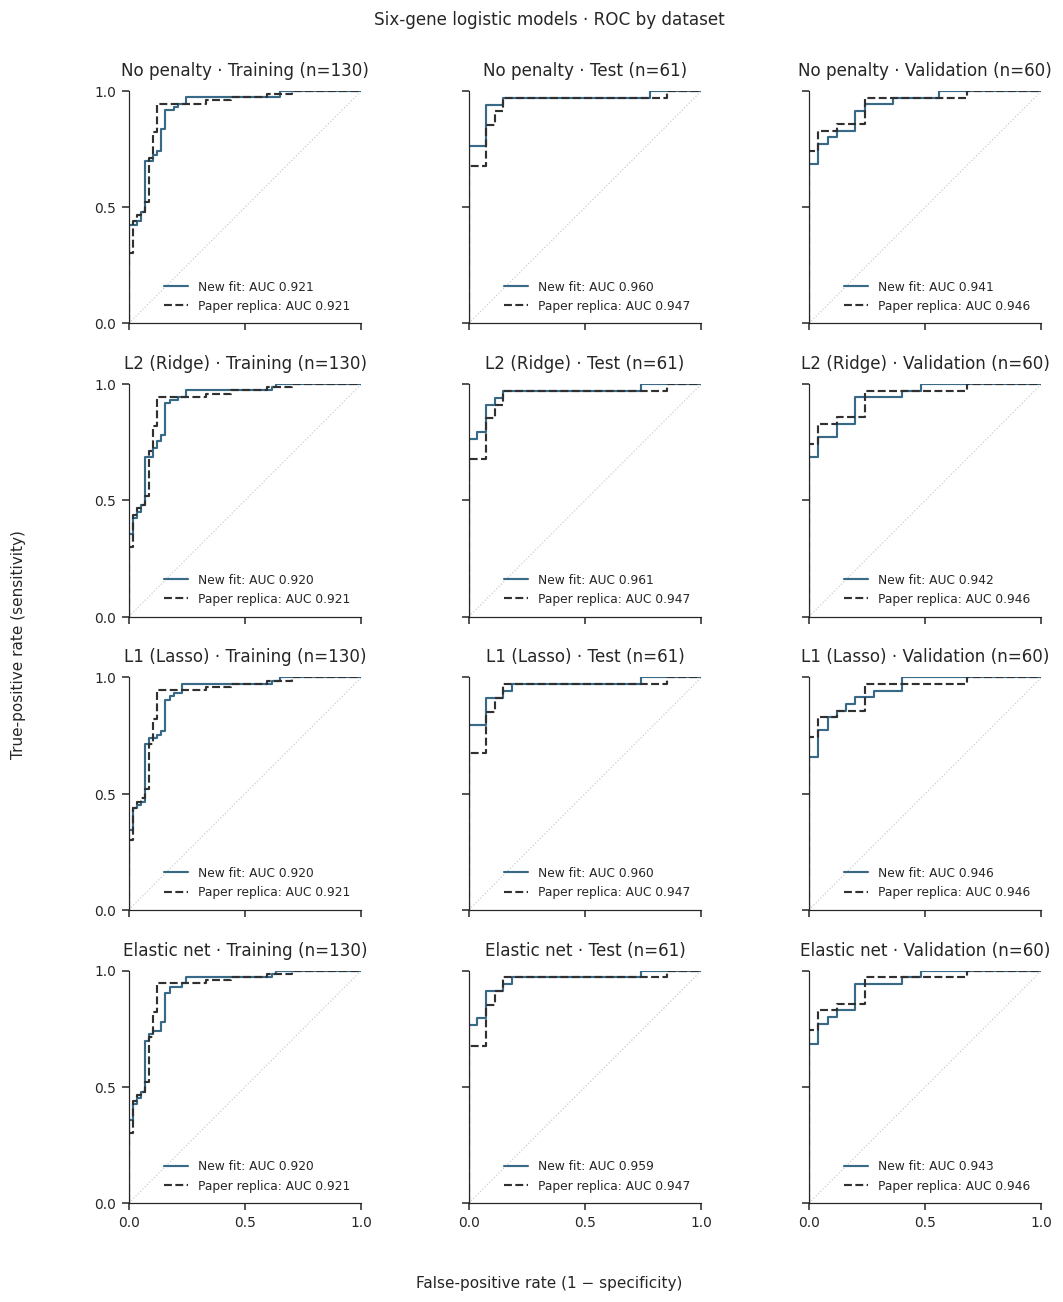

In [17]:
figure, axes = plt.subplots(
    len(controls), len(split_labels), figsize=(10.2, 12), sharex=True, sharey=True
)
for row, (name, estimator) in enumerate(controls.items()):
    for column, (split, labels) in enumerate(split_labels.items()):
        axis = axes[row, column]
        for model_name, color, linestyle in [
            (name, NEW_COLOR, "-"), (paper_name, PAPER_COLOR, "--")
        ]:
            curve = roc_points.loc[
                roc_points.model.eq(model_name) & roc_points.split.eq(split)
            ]
            auc = roc_auc_score(labels, all_probabilities[model_name][split])
            label = "New fit" if model_name == name else "Paper replica"
            axis.plot(
                curve.false_positive_rate, curve.sensitivity,
                color=color, linestyle=linestyle, linewidth=1.4,
                label=f"{label}: AUC {auc:.3f}",
            )
        axis.plot([0, 1], [0, 1], color="0.8", linestyle=":", linewidth=0.8, zorder=0)
        axis.set(
            title=f"{model_labels[estimator.penalty]} · {SPLIT_NAMES[split]} (n={len(labels)})",
            xlim=(0, 1), ylim=(0, 1),
            xticks=[0, 0.5, 1], yticks=[0, 0.5, 1], aspect="equal",
        )
        axis.legend(loc="lower right", frameon=False, fontsize=8)
        axis.grid(False)
figure.supxlabel("False-positive rate (1 − specificity)", fontsize=10)
figure.supylabel("True-positive rate (sensitivity)", fontsize=10)
figure.suptitle("Six-gene logistic models · ROC by dataset", fontsize=11)
figure.tight_layout(rect=(0.02, 0.02, 1, 0.98), w_pad=1, h_pad=1.5)
save_figure(figure, "logistic_roc_curves")
plt.show()


### Read the regularization comparison

Generate this interpretation from the current settings. A larger AUC is a
numerical change on this test cohort, not proof of better future performance.
The models remain additive in log odds. No penalty adds gene-pair terms.

In [18]:
control_lookup = control_results.set_index("model")
baseline_auc = control_lookup.loc[unpenalized_name, "test_auc"]
changes = control_results.assign(
    test_auc_change_vs_no_penalty=lambda table: table.test_auc - baseline_auc
)
changes.to_csv(OUTPUT / "logistic_regularization_changes.csv", index=False)
best_control = control_results.loc[control_results.test_auc.idxmax()]
l1_name = next(name for name, model in controls.items() if model.penalty == "l1")
l1_nonzero = int(control_lookup.loc[l1_name, "nonzero_weights"])
penalty_intervals = paired_results.iloc[1:]
auc_spans_zero = (
    penalty_intervals.auc_lower.le(0) & penalty_intervals.auc_upper.ge(0)
).sum()
loss_spans_zero = (
    penalty_intervals.loss_lower.le(0) & penalty_intervals.loss_upper.ge(0)
).sum()
display(
    Markdown(
        f"**Current settings:** The paper replica has test AUC **{paper_result.test_auc.iloc[0]:.4f}**. "
        f"The new no-penalty GLM has AUC **{baseline_auc:.4f}**. "
        f"The highest control AUC is **{best_control.test_auc:.4f}** ({best_control.model}). "
        f"L1 retains **{l1_nonzero} of {len(paper_genes)}** nonzero gene weights. "
        "A penalty does not necessarily improve both ranking and probability fit. "
        f"Paired intervals span zero for **{auc_spans_zero} of {len(penalty_intervals)}** penalty AUC changes "
        f"and **{loss_spans_zero} of {len(penalty_intervals)}** log-loss changes. "
        "These intervals do not include training or model-selection uncertainty. "
        "These fixed settings have not been selected by cross-validation."
    )
)

**Current settings:** The paper replica has test AUC **0.9466**. The new no-penalty GLM has AUC **0.9597**. The highest control AUC is **0.9608** (Logistic GLM: L2 (Ridge)). L1 retains **6 of 6** nonzero gene weights. A penalty does not necessarily improve both ranking and probability fit. Paired intervals span zero for **3 of 3** penalty AUC changes and **3 of 3** log-loss changes. These intervals do not include training or model-selection uncertainty. These fixed settings have not been selected by cross-validation.

## 5. Define one shared model screen

Use nine LazyPredict classifiers plus XGBoost and a small neural network. Linear
SVM (`LinearSVC`) and RBF SVM (`SVC`) are already included. Keep the existing
LazyPredict defaults; define the two additions once below. Every input set and
GFS variant reuses these settings. This is a fixed screen, not a hyperparameter
search; test and validation outcomes do not choose the model settings.

| Classifiers | Prediction structure |
|---|---|
| LogisticRegression, RidgeClassifier, LinearSVC | Additive linear score; no pair terms |
| GaussianNB | Nonlinear single-gene terms, additive in log odds; no pair terms |
| KNN, RBF SVM, random forest, ExtraTrees | Can represent joint, nonlinear effects |
| XGBoost | 100 boosted trees, depth 2, learning rate 0.05 |
| Neural network | One hidden layer with 8 ReLU units, L2 penalty 0.1 |
| Dummy | No expression signal |

The network uses L-BFGS, which scikit-learn recommends considering for small
datasets. These fixed choices are starting configurations, not tuned optima.
The broad all-gene network still has many weights despite its small hidden layer.
Both additions use the same mean imputation and standardization as the numeric
LazyPredict pipelines. Fit preprocessing and models on training samples only,
then score each fitted pipeline on all three splits without refitting.

`RidgeClassifier` uses squared loss; it is not Ridge logistic regression.
Compute ROC AUC from continuous scores. Save all model settings and warnings;
the supplementary `*_lazy_summary.csv` files contain only LazyPredict's nine
models, while the comparison tables and prediction exports contain every model.
Stop on failed fits or nonconvergence of the added models.

Sources: [XGBoost parameters](https://xgboost.readthedocs.io/en/release_3.0.0/parameter.html),
[MLPClassifier](https://scikit-learn.org/1.6/modules/generated/sklearn.neural_network.MLPClassifier.html).


In [19]:
LAZY_CLASSES = [
    DummyClassifier,
    LogisticRegression,
    RidgeClassifier,
    LinearSVC,
    GaussianNB,
    KNeighborsClassifier,
    SVC,
    RandomForestClassifier,
    ExtraTreesClassifier,
]


EXTRA_MODELS = {
    "XGBClassifier": XGBClassifier(
        n_estimators=100, max_depth=2, learning_rate=0.05,
        objective="binary:logistic", eval_metric="logloss", tree_method="hist",
        n_jobs=1, random_state=SEED,
    ),
    "MLPClassifier": MLPClassifier(
        hidden_layer_sizes=(8,), solver="lbfgs", alpha=0.1,
        max_iter=5000, max_fun=50000, random_state=SEED,
    ),
}


def run_lazy_models(name, features_by_split):
    train_features, test_features = features_by_split["train"], features_by_split["test"]
    for split, features in features_by_split.items():
        assert features.index.equals(split_metadata[split].index)
        assert features.columns.equals(train_features.columns)
    benchmark = LazyClassifier(
        classifiers=LAZY_CLASSES,
        random_state=SEED,
        ignore_warnings=False,
        verbose=0,
        cv=None,
        n_jobs=1,
    )
    with warnings.catch_warnings(record=True) as captured, threadpool_limits(limits=1):
        warnings.simplefilter("always")
        summary, _ = benchmark.fit(
            train_features.astype(float), test_features.astype(float), y_train, y_test
        )
    missing = {model.__name__ for model in LAZY_CLASSES} - set(summary.index)
    if missing:
        raise RuntimeError(f"LazyPredict failed for {missing}: {benchmark.errors}")
    models = benchmark.models
    with warnings.catch_warnings(record=True) as extra_warnings, threadpool_limits(limits=1):
        warnings.simplefilter("always")
        warnings.simplefilter("error", ConvergenceWarning)
        for model_name, estimator in EXTRA_MODELS.items():
            models[model_name] = make_pipeline(
                SimpleImputer(strategy="mean"), StandardScaler(), clone(estimator)
            ).fit(train_features, y_train)
    rows, predictions, settings = [], {}, {}
    for model_name, model in models.items():
        row, scores = auc_result(model_name, model, features_by_split)
        rows.append(row)
        predictions[model_name] = scores
        settings[model_name] = model.steps[-1][1].get_params()
    summary.to_csv(OUTPUT / f"{name}_lazy_summary.csv")
    (OUTPUT / f"{name}_settings.json").write_text(
        json.dumps(settings, indent=2, default=str)
    )
    messages = sorted({str(item.message) for item in [*captured, *extra_warnings]})
    (OUTPUT / f"{name}_warnings.json").write_text(json.dumps(messages, indent=2))
    if messages:
        print(f"{name}: {len(messages)} warning types; see {name}_warnings.json.")
    return pd.DataFrame(rows), predictions, models

### Compare all new models with the paper replica on six genes

Run the shared screen once on the same six-gene matrices. Combine its results with the
four logistic controls and the paper replica. Only the model settings and classifier
preprocessing differ. The blue markers show new fits. The dark row is the paper
replica. No other genes enter these models. The plot ranks rows by test AUC;
open marks are training, filled circles/diamonds are test, and filled triangles
are validation scores. All fits use the same 130 training participants and are
evaluated on 61 test and 60 validation participants using original VST inputs.

The table follows the same test-AUC order. Values are shown to four decimals;
bold shaded cells mark the highest displayed AUC in each dataset, including ties.

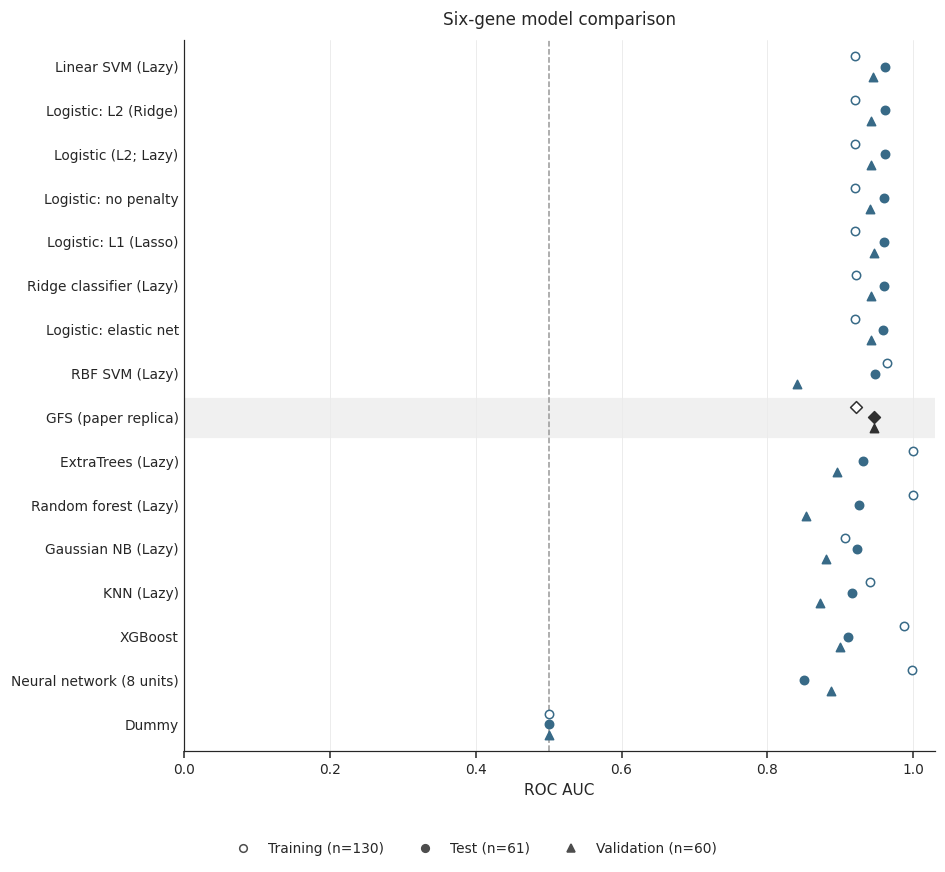

Source,Model,Training AUC,Test AUC,Validation AUC
New,Linear SVM (Lazy),0.9202,0.9608,0.9451
New,Logistic: L2 (Ridge),0.9197,0.9608,0.9417
New,Logistic (L2; Lazy),0.9200,0.9608,0.9417
New,Logistic: no penalty,0.9209,0.9597,0.9406
New,Logistic: L1 (Lasso),0.9205,0.9597,0.9463
New,Ridge classifier (Lazy),0.9217,0.9597,0.9429
New,Logistic: elastic net,0.9202,0.9586,0.9429
New,RBF SVM (Lazy),0.9642,0.9477,0.8411
Paper replica,GFS,0.9212,0.9466,0.9463
New,ExtraTrees (Lazy),1.0000,0.9319,0.8960


In [20]:
six_lazy_results, six_lazy_predictions, six_lazy_models = run_lazy_models(
    "six_genes", paper_inputs
)
six_results = pd.concat(
    [paper_result, control_results, six_lazy_results], ignore_index=True
)
figure, axis = plt.subplots(figsize=(8.7, max(6.2, 0.42 * len(six_results) + 1.3)))
ranked_six = draw_auc_panel(axis, six_results, "Six-gene model comparison")
add_auc_legend(figure)
figure.tight_layout(rect=(0, 0.07, 1, 1))
save_figure(figure, "six_gene_comparison")
ranked_six.to_csv(OUTPUT / "six_gene_results.csv", index=False)
plt.show()

display_auc_table(ranked_six)


## 6. Change the gene set under one normalization protocol

Use the VST reference fitted on training counts and apply it to all three splits. Compare the
repository's 142 DE genes with all genes that vary in training counts. Reuse the
same LazyPredict screen for both sets. These are new experiments.

The paper's original VST was fitted separately within each split. Thus, this
experiment is separate from the matched six-gene comparison above. Do not subtract
its AUCs from the paper AUC to isolate a gene-count effect.

In [21]:
training_log_means = reference_log_means(train_counts)
expression_by_split = {
    split: variance_stabilize(counts, training_log_means, reference["training_vst"])
    for split, counts in {
        "train": train_counts, "test": test_counts, "val": validation_counts
    }.items()
}
all_variable_genes = train_counts.columns[train_counts.nunique(axis=0) > 1]
feature_sets = {
    "DE genes": training_de_genes.index,
    "All variable genes": all_variable_genes,
}
assert training_de_genes.index.isin(all_variable_genes).all()
broad_results, broad_predictions = [], {}
for feature_set, genes in feature_sets.items():
    results, predictions, _ = run_lazy_models(
        feature_set.replace(" ", "_").lower(),
        {split: expression[genes] for split, expression in expression_by_split.items()},
    )
    broad_results.append(results.assign(feature_set=feature_set))
    broad_predictions[feature_set] = predictions
broad_results = pd.concat(broad_results, ignore_index=True)
broad_results.to_csv(OUTPUT / "gene_set_results.csv", index=False)

High-dimensional dataset (52990 features). Some models may be slow or fail. Consider dimensionality reduction.


### Expression input for the biological follow-ups

Export the existing training-reference VST, using a label-independent training detection filter for broad expression analyses. The companion notebooks verify these input and artifact hashes before reuse. This export does not alter the model fits above.

In [ ]:
# Reuse this training-reference expression matrix in the biology notebooks.
training_expression = pd.concat(expression_by_split.values())
np.savez_compressed(
    REFERENCE / "expression_training_vst.npz",
    values=training_expression.to_numpy(),
    samples=training_expression.index.to_numpy(dtype=str),
    genes=training_expression.columns.to_numpy(dtype=str),
)
minimum_participants = int(np.ceil(0.1 * len(train_counts)))
eligible_genes = train_counts.columns[(train_counts >= 10).sum(axis=0) >= minimum_participants]
pd.Series(eligible_genes, name="gene_id").to_csv(REFERENCE / "eligible_genes.csv", index=False)
training_size_factors = np.exp(
    np.log(counts_all[training_log_means.index].replace(0, np.nan)).subtract(training_log_means).median(axis=1)
)
training_size_factors.to_csv(REFERENCE / "training_reference_size_factors.csv", header=["size_factor"])
input_paths = [REFERENCE / "reference.json"]
input_paths += [DATA / f"counts.{split}.tsv" for split in SPLIT_NAMES]
input_paths += [DATA / f"metadata.{split}.tsv" for split in SPLIT_NAMES]
artifact_paths = [REFERENCE / name for name in [
    "expression_training_vst.npz", "eligible_genes.csv", "training_reference_size_factors.csv"
]]
expression_manifest = {
    "inputs": {str(path.relative_to(REPOSITORY)): hashlib.sha256(path.read_bytes()).hexdigest()
               for path in input_paths},
    "artifacts": {str(path.relative_to(REPOSITORY)): hashlib.sha256(path.read_bytes()).hexdigest()
                  for path in artifact_paths},
    "normalization": "training-reference parametric DESeq2 VST",
    "version": 1,
}
(REFERENCE / "expression_training_vst.json").write_text(json.dumps(expression_manifest, indent=2))
print(f"Exported {len(training_expression)} participants and {len(eligible_genes):,} adequately expressed genes.")

Exported 251 participants and 11,279 adequately expressed genes.


### Plot DE genes and all variable genes

Use separate panels with identical AUC scales. Each panel has its own test-AUC
order. All rows are new fits. The table reports the paired change in AUC within each split
when the same classifier receives all variable genes instead of DE genes.
Both arms use the same samples, training-fitted VST, and classifier settings.
These gene sets do not reproduce the paper's unavailable 113-gene input list.

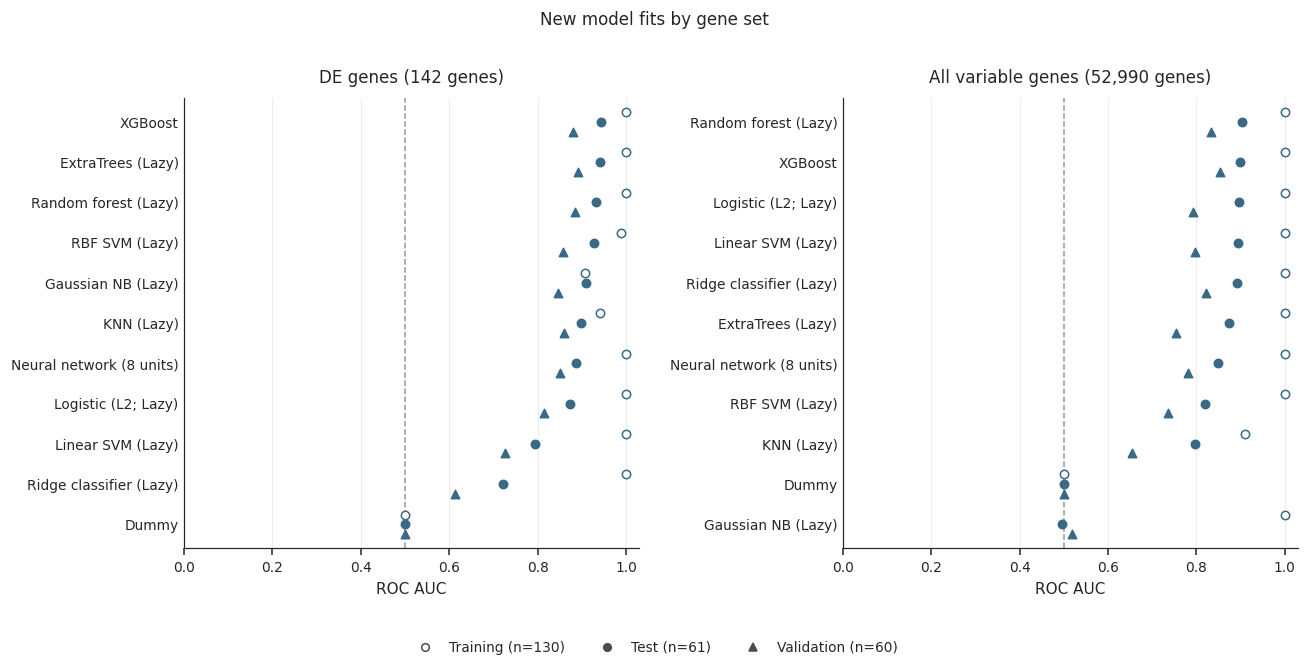

feature_set                   All variable genes  DE genes  All minus DE
split model                                                             
train DummyClassifier                     0.5000    0.5000        0.0000
      ExtraTreesClassifier                1.0000    1.0000        0.0000
      GaussianNB                          1.0000    0.9063        0.0937
      KNeighborsClassifier                0.9111    0.9405       -0.0294
      LinearSVC                           1.0000    1.0000        0.0000
      LogisticRegression                  1.0000    1.0000        0.0000
      MLPClassifier                       1.0000    1.0000        0.0000
      RandomForestClassifier              1.0000    1.0000        0.0000
      RidgeClassifier                     1.0000    1.0000        0.0000
      SVC                                 1.0000    0.9885        0.0115
      XGBClassifier                       1.0000    1.0000        0.0000
test  DummyClassifier                     0.5000    0.5000        0.0000
      ExtraTreesClassifier                0.8742    0.9406       -0.0664
      GaussianNB                          0.4967    0.9085       -0.4118
      KNeighborsClassifier                0.7974    0.8976       -0.1002
      LinearSVC                           0.8943    0.7952        0.0991
      LogisticRegression                  0.8976    0.8736        0.0240
      MLPClassifier                       0.8497    0.8867       -0.0370
      RandomForestClassifier              0.9041    0.9330       -0.0289
      RidgeClassifier                     0.8911    0.7222        0.1688
      SVC                                 0.8192    0.9281       -0.1089
      XGBClassifier                       0.8998    0.9434       -0.0436
val   DummyClassifier                     0.5000    0.5000        0.0000
      ExtraTreesClassifier                0.7549    0.8920       -0.1371
      GaussianNB                          0.5189    0.8469       -0.3280
      KNeighborsClassifier                0.6543    0.8594       -0.2051
      LinearSVC                           0.7966    0.7257        0.0709
      LogisticRegression                  0.7931    0.8149       -0.0217
      MLPClassifier                       0.7806    0.8514       -0.0709
      RandomForestClassifier              0.8337    0.8846       -0.0509
      RidgeClassifier                     0.8217    0.6137        0.2080
      SVC                                 0.7360    0.8583       -0.1223
      XGBClassifier                       0.8537    0.8811       -0.0274

In [22]:
figure, axes = plt.subplots(1, 2, figsize=(12, max(5.2, 0.45 * (len(LAZY_CLASSES) + len(EXTRA_MODELS)) + 1.2)))
for axis, (feature_set, genes) in zip(axes, feature_sets.items()):
    subset = broad_results.loc[broad_results.feature_set.eq(feature_set)]
    draw_auc_panel(axis, subset, f"{feature_set} ({len(genes):,} genes)")
add_auc_legend(figure)
figure.suptitle("New model fits by gene set", fontsize=11)
figure.tight_layout(rect=(0, 0.09, 1, 0.97), w_pad=2)
save_figure(figure, "de_vs_all_genes")
plt.show()
gene_set_change = broad_results.melt(
    id_vars=["model", "feature_set"], value_vars=auc_columns,
    var_name="split", value_name="auc",
)
gene_set_change["split"] = gene_set_change["split"].str.removesuffix("_auc")
gene_set_change = gene_set_change.pivot(
    index=["split", "model"], columns="feature_set", values="auc"
)
gene_set_change["All minus DE"] = (
    gene_set_change["All variable genes"] - gene_set_change["DE genes"]
)
gene_set_change = gene_set_change.reindex(split_labels, level="split")
gene_set_change.to_csv(OUTPUT / "gene_set_auc_change.csv")
display(gene_set_change.round(4))

## 7. Select genes separately for each classifier

Run two greedy forward searches for the ten predictive classifiers,
then compare each with a separate search that can revise its selected genes.
Each classifier chooses its own genes from the same 142 training DE candidates.
Dummy remains a chance reference and does not undergo feature selection.

| Method | Candidate score | Stopping rule |
|---|---|---|
| Paper rule | Training AUC + sensitivity + specificity at the first best Youden threshold | Accept a gain strictly greater than 0.01; no six-gene cap |
| CV AUC | Mean AUC in five stratified folds within training | Accept a positive CV-AUC gain; stop when no addition improves it |

Both use the paper's correlation tie-breaker: lowest absolute **mean** Pearson
correlation with selected genes, then candidate order. Keep each classifier's
settings from the shared screen and the same seed. These are new model-specific selection runs;
they do not reconstruct the paper's unavailable historical classifier searches.

For a matched comparison, **both methods use the same paper-style VST inputs**:
normalize each split independently, using the saved original dispersion trends.
The six known genes must match the existing paper feature export. This preserves
comparability with the earlier six-gene analysis. The preceding DE/all-gene
experiment uses a different, training-reference normalization protocol.

Only training outcomes enter selection. Test and validation outcomes enter the
final evaluation. The CV folds refit imputation, scaling, and the classifier.
The DE candidate pool and VST reference were already estimated using all training
samples, so the inner-CV scores guide selection; they are not unbiased estimates
of the complete discovery pipeline. Both evaluation sets have now been inspected,
so these additional comparisons remain exploratory.

The [audited original GFS](../Files_For_Manuscript/gene_interactions_reference/paper_input_audit/gfs_selection/README.md)
defines the paper rule. The CV variant uses the same forward-search structure as
[sequential feature selection](https://scikit-learn.org/1.6/modules/generated/sklearn.feature_selection.SequentialFeatureSelector.html).
One shared loop below exposes the paper's stopping and tie rules and saves every
candidate score for both methods. Neither search has a preset gene count.
CV gains within `1e-12` are treated as numerical ties, not improvements.

In [23]:
GFS_JOBS = 16  # Candidate-level parallelism; each model/fold remains single-threaded.
CV_SCORE_TOL = 1e-12  # Numerical equality, not a substantive minimum gain.
PAPER_MIN_GAIN = paper_model["gfs_settings"]["minimum_score_gain"]
GFS_OUTPUT = OUTPUT / "gfs"
GFS_OUTPUT.mkdir(exist_ok=True)
gfs_score_cache, gfs_gene_sets = {}, {}

candidate_table = pd.read_csv(
    REFERENCE / "paper_input_audit/training_candidates.tsv", sep="\t", index_col="gene_id"
).sort_values("padj", kind="stable")
candidate_table = candidate_table.query("padj < 0.05 and baseMean > 100")
candidate_genes = candidate_table.index.tolist()
assert len(candidate_genes) == 142
assert set(candidate_genes) == set(training_de_genes.index)
gene_names_by_id = candidate_table.gene_name.to_dict()

gfs_inputs = {}
for split, counts in {
    "train": train_counts, "test": test_counts, "val": validation_counts
}.items():
    transformed = variance_stabilize(
        counts, reference_log_means(counts), paper_model["split_vst"][split]
    )
    gfs_inputs[split] = transformed.loc[split_metadata[split].index, candidate_genes]
    np.testing.assert_allclose(
        gfs_inputs[split][paper_genes], paper_inputs[split], rtol=0, atol=1e-12
    )

# Export the exact model inputs for the separate interpretation notebook.
pd.concat(gfs_inputs, names=["split", "sample_id"]).to_csv(GFS_OUTPUT / "expression_vst.csv")

gfs_templates = {
    name: make_pipeline(
        SimpleImputer(strategy="mean"), StandardScaler(), clone(model.steps[-1][1])
    )
    for name, model in six_lazy_models.items()
    if name != "DummyClassifier"
}
# LazyPredict's original ColumnTransformer binds column names; these equivalent
# numeric pipelines can accept a changing subset of genes during selection.
with threadpool_limits(limits=1):
    for name, template in gfs_templates.items():
        fitted = clone(template).fit(paper_train, y_train)
        np.testing.assert_allclose(
            positive_scores(fitted, paper_test), six_lazy_predictions[name]["test"],
            rtol=0, atol=1e-12,
        )

gfs_folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(
    gfs_inputs["train"], y_train
))
fold_ids = np.empty(len(y_train), dtype=int)
for fold, (fit_indices, score_indices) in enumerate(gfs_folds, 1):
    assert set(fit_indices).isdisjoint(score_indices)
    fold_ids[score_indices] = fold
pd.DataFrame({"sample_id": train_metadata.index, "selection_fold": fold_ids}).to_csv(
    GFS_OUTPUT / "cv_folds.csv", index=False
)
_ = (GFS_OUTPUT / "settings.json").write_text(json.dumps({
    "seed": SEED, "workers": GFS_JOBS, "candidate_genes": candidate_genes,
    "paper_minimum_gain": PAPER_MIN_GAIN, "cv_minimum_gain": 0.0,
    "cv_numerical_tolerance": CV_SCORE_TOL, "preset_gene_count": None,
    "cv_folds": 5, "normalization": "original independent VST in each split",
    "tie_breaker": "absolute mean training correlation, then candidate order",
    "refinement": "best improving single-gene addition, removal, or replacement",
    "refinement_order": "forward-selected genes, then remaining candidate order",
    "refinement_removal_ties": "no incoming correlation; original candidate order",
    "models": {name: model.steps[-1][1].get_params() for name, model in gfs_templates.items()},
}, indent=2, default=str))


### Score candidate additions

The paper score matches pROC's automatic ROC direction, chosen from the two
training-class medians, and its first maximum Youden threshold. Final reported
AUCs always use the usual TB-positive score direction, as in the existing helper.

For CV, reuse `positive_scores()` so margins and Gaussian NB log probabilities
are handled consistently. Candidate workers receive training data only. Any
failed fit or convergence warning stops the search instead of silently dropping
a candidate. Parallelize candidates; keep each model and fold evaluation serial.

In [24]:
def paper_training_metrics(labels, scores):
    direction = 1 if np.median(scores[labels == 0]) <= np.median(scores[labels == 1]) else -1
    oriented = direction * scores
    false_positive_rate, sensitivity, _ = roc_curve(labels, oriented, drop_intermediate=False)
    sensitivity, specificity = sensitivity[::-1], 1 - false_positive_rate[::-1]
    best = np.argmax(sensitivity + specificity - 1)
    auc = roc_auc_score(labels, oriented)
    return {
        "selection_score": specificity[best] + sensitivity[best] + auc,
        "selection_auc": auc, "sensitivity": sensitivity[best],
        "specificity": specificity[best], "direction": "<" if direction == 1 else ">",
    }


def cv_auc(estimator, features, labels):
    return roc_auc_score(labels, positive_scores(estimator, features))


def score_candidate(template, features, labels, genes, method, folds):
    with warnings.catch_warnings(), threadpool_limits(limits=1):
        warnings.simplefilter("error", ConvergenceWarning)
        if method == "paper":
            fitted = clone(template).fit(features[genes], labels)
            return paper_training_metrics(labels, positive_scores(fitted, features[genes]))
        fold_scores = cross_val_score(
            template, features[genes], labels, scoring=cv_auc, cv=folds,
            n_jobs=1, error_score="raise",
        )
    return {
        "selection_score": fold_scores.mean(), "fold_sd": fold_scores.std(ddof=1),
        **{f"fold_{i}_auc": score for i, score in enumerate(fold_scores, 1)},
    }



def score_subsets(template, features, labels, subsets, method, folds, cache):
    """Reuse exact scores; ordered keys preserve seeded model behavior."""
    keys = [tuple(genes) for genes in subsets]
    missing = list(dict.fromkeys(key for key in keys if key not in cache))
    if missing:
        with parallel_config(backend="loky", n_jobs=GFS_JOBS, inner_max_num_threads=1):
            metrics = Parallel()(
                delayed(score_candidate)(template, features, labels, list(genes), method, folds)
                for genes in missing
            )
        cache.update(zip(missing, metrics))
    return [cache[key] for key in keys]


### Use one forward-selection loop

At each step, score every candidate added to the current gene set. Rank candidates
by the existing score and correlation tie-breaker. Accept an improvement greater
than 0.01 for the paper rule, or a positive CV-AUC improvement beyond numerical
precision for CV. Stop at the first step with no qualifying improvement.

The paper search still reevaluates already-selected genes, as its R source does;
duplicate terms are removed before fitting. CV considers remaining genes. There
is no preset gene count. Save every candidate score and winning step. Cache scores
within each model and criterion so the later refinement can reuse them.


In [25]:
def forward_select(template, features, labels, method, folds, output_prefix, cache):
    assert method in {"paper", "cv"}
    selected, candidate_history, steps = [], [], []
    correlations = features.corr()
    previous_score = 0.0 if method == "paper" else 0.5
    minimum_gain = PAPER_MIN_GAIN if method == "paper" else CV_SCORE_TOL
    for step in range(1, features.shape[1] + 1):
        candidates = [gene for gene in features if method == "paper" or gene not in selected]
        subsets = [list(dict.fromkeys([*selected, gene])) for gene in candidates]
        metrics = score_subsets(template, features, labels, subsets, method, folds, cache)
        trials = pd.DataFrame(metrics, index=pd.Index(candidates, name="gene_id"))
        assert np.isfinite(trials.selection_score).all()
        trials["correlation"] = [
            abs(correlations.loc[gene, selected].mean()) if selected else np.nan
            for gene in candidates
        ]
        best_gene = trials.sort_values(
            ["selection_score", "correlation"], ascending=[False, True], kind="stable"
        ).index[0]
        best = trials.loc[best_gene]
        gain = best.selection_score - previous_score
        accepted = gain > minimum_gain
        trials["step"] = step
        trials["is_winner"] = trials.index == best_gene
        candidate_history.append(trials.reset_index())
        steps.append({
            "step": step, "gene_id": best_gene, "gene_name": gene_names_by_id[best_gene],
            **best.to_dict(), "score_gain": gain, "accepted": accepted,
        })
        pd.concat(candidate_history, ignore_index=True).to_csv(
            GFS_OUTPUT / f"{output_prefix}_candidates.csv", index=False
        )
        pd.DataFrame(steps).to_csv(GFS_OUTPUT / f"{output_prefix}_steps.csv", index=False)
        if not accepted:
            break
        assert best_gene not in selected
        selected.append(best_gene)
        previous_score = best.selection_score
    if not selected:
        raise ValueError(f"{output_prefix}: no gene improves the initial score.")
    return selected, pd.DataFrame(steps)


def run_gfs(method, refine=False):
    variant = f"{method}_refined" if refine else method
    rows, predictions, selections = [], {}, []
    for name, template in gfs_templates.items():
        cache = gfs_score_cache.setdefault((method, name), {})
        arguments = (template, gfs_inputs["train"], y_train, method, gfs_folds,
                     f"{variant}_{name}", cache)
        if refine:
            genes, steps = refine_selection(*arguments, gfs_gene_sets[(method, name)])
        else:
            genes, steps = forward_select(*arguments)
        gfs_gene_sets[(variant, name)] = genes
        inputs = {split: features[genes] for split, features in gfs_inputs.items()}
        with warnings.catch_warnings(), threadpool_limits(limits=1):
            warnings.simplefilter("error", ConvergenceWarning)
            fitted = clone(template).fit(inputs["train"], y_train)
        row, scores = auc_result(name, fitted, inputs)
        row.update(
            method="Paper rule" if method == "paper" else "CV AUC",
            search="Forward + revisions" if refine else "Forward",
            selected_genes=", ".join(gene_names_by_id[gene] for gene in genes),
            selection_score=cache[tuple(genes)]["selection_score"],
        )
        rows.append(row)
        predictions[name] = scores
        selections.extend({"model": name, "order": order, "gene_id": gene,
                           "gene_name": gene_names_by_id[gene]} for order, gene in enumerate(genes, 1))
        pd.DataFrame(rows).to_csv(GFS_OUTPUT / f"{variant}_results.csv", index=False)
        pd.DataFrame(selections).to_csv(GFS_OUTPUT / f"{variant}_selected_genes.csv", index=False)
        print(f"{row['method']} / {row['search']}: {name} selected {len(genes)} genes.", flush=True)
    return pd.DataFrame(rows), predictions


### Run the paper's selection rule

Use the original training composite score and strict 0.01 improvement threshold.
The number of selected genes can differ across classifiers. Flexible models can
reach a perfect training score with very few genes; the held-out AUCs below show
whether that apparent fit transfers to test and validation samples.

In [26]:
paper_gfs_results, paper_gfs_predictions = run_gfs("paper")


Paper rule / Forward: LogisticRegression selected 3 genes.


Paper rule / Forward: RidgeClassifier selected 4 genes.


Paper rule / Forward: LinearSVC selected 4 genes.


Paper rule / Forward: GaussianNB selected 6 genes.


Paper rule / Forward: KNeighborsClassifier selected 3 genes.


Paper rule / Forward: SVC selected 7 genes.


Paper rule / Forward: RandomForestClassifier selected 1 genes.


Paper rule / Forward: ExtraTreesClassifier selected 1 genes.


Paper rule / Forward: XGBClassifier selected 6 genes.


Paper rule / Forward: MLPClassifier selected 5 genes.


### Run the fivefold-CV alternative

Use the same five training folds for every candidate and classifier. Each model
adds genes only while its best addition improves mean CV AUC, then fits that
selected subset on all 130 training participants. The number of genes is learned
from training scores. Test and validation outcomes never determine selection.

This remains a greedy path: stopping at its first local peak can miss a useful
later combination. The separate refinement below allows earlier choices to change.


In [27]:
cv_gfs_results, cv_gfs_predictions = run_gfs("cv")


CV AUC / Forward: LogisticRegression selected 5 genes.


CV AUC / Forward: RidgeClassifier selected 5 genes.


CV AUC / Forward: LinearSVC selected 4 genes.


CV AUC / Forward: GaussianNB selected 8 genes.


CV AUC / Forward: KNeighborsClassifier selected 3 genes.


CV AUC / Forward: SVC selected 13 genes.


CV AUC / Forward: RandomForestClassifier selected 10 genes.


CV AUC / Forward: ExtraTreesClassifier selected 4 genes.


CV AUC / Forward: XGBClassifier selected 6 genes.


CV AUC / Forward: MLPClassifier selected 6 genes.


### Allow selected genes to be removed or replaced

Start a separate refinement from each forward-selected subset. Evaluate all
single-gene additions, removals, and one-for-one replacements, accept the best
qualifying score improvement, and repeat. Keep the same score, folds, model
settings, candidate pool, preprocessing, and gain threshold for each criterion.
At least one gene must remain; there is no preset maximum beyond the 142 candidates.

Freeze feature order as the starting selected genes followed by the remaining
candidate order. This preserves the forward model exactly and makes each subset's
score reproducible even for seeded forests. Cached scores use this exact order.
For additions/replacements retain the correlation tie-break against the retained
genes. Deletions have no incoming gene: their correlation is undefined, so exact
score ties favor defined incoming correlations, then original candidate order.

Stop when no single add/remove/swap meets the gain threshold. This removes irreversible
choices but is still a local search; it does not guarantee a global optimum or
find every interaction. The unchanged paper score can still saturate at 3, in
which case no strictly improving revision exists. More search can also overfit
training/CV scores; test and validation remain evaluation-only.


In [28]:
def refine_selection(template, features, labels, method, folds, output_prefix, cache,
                     initial_genes):
    selected = list(initial_genes)
    feature_order = selected + [gene for gene in features if gene not in selected]
    positions = {gene: i for i, gene in enumerate(feature_order)}
    correlations = features.corr()
    minimum_gain = PAPER_MIN_GAIN if method == "paper" else CV_SCORE_TOL
    ceiling = 3.0 if method == "paper" else 1.0
    current = score_subsets(template, features, labels, [selected], method, folds, cache)[0]
    history, steps = [], [{
        "step": 0, "action": "start", "removed_gene": None, "added_gene": None,
        "genes": json.dumps(selected), "n_features": len(selected),
        **current, "score_gain": 0.0, "accepted": True, "stop_reason": "",
    }]
    while True:
        if ceiling - current["selection_score"] <= minimum_gain:
            steps[-1]["stop_reason"] = "No qualifying gain possible below score ceiling"
            break
        proposals = []
        for gene in features:
            if gene in selected:
                if len(selected) > 1:
                    retained = [item for item in selected if item != gene]
                    proposals.append({"action": "remove", "removed_gene": gene,
                                      "added_gene": None, "genes": retained,
                                      "correlation": np.nan})
            else:
                # None means addition; otherwise replace that selected gene.
                for removed in [None, *[item for item in features if item in selected]]:
                    retained = [item for item in selected if item != removed]
                    genes = sorted([*retained, gene], key=positions.get)
                    proposals.append({
                        "action": "add" if removed is None else "swap",
                        "removed_gene": removed, "added_gene": gene, "genes": genes,
                        "correlation": abs(correlations.loc[gene, retained].mean())
                                       if retained else np.nan,
                    })
        step = len(steps)
        print(f"{output_prefix}: checking {len(proposals)} revisions at {len(selected)} genes.",
              flush=True)
        metrics = score_subsets(
            template, features, labels, [row["genes"] for row in proposals], method, folds, cache
        )
        trials = pd.DataFrame([
            {**row, **score, "genes": json.dumps(row["genes"]),
             "n_features": len(row["genes"]), "step": step}
            for row, score in zip(proposals, metrics)
        ])
        assert np.isfinite(trials.selection_score).all()
        best_index = trials.sort_values(
            ["selection_score", "correlation"], ascending=[False, True], kind="stable"
        ).index[0]
        best = trials.loc[best_index]
        gain = best.selection_score - current["selection_score"]
        accepted = gain > minimum_gain
        trials["is_winner"] = trials.index == best_index
        history.append(trials)
        steps.append({**best.to_dict(), "score_gain": gain, "accepted": accepted,
                      "stop_reason": "" if accepted else "No qualifying add/remove/swap improvement"})
        pd.concat(history, ignore_index=True).to_csv(
            GFS_OUTPUT / f"{output_prefix}_candidates.csv", index=False
        )
        pd.DataFrame(steps).to_csv(GFS_OUTPUT / f"{output_prefix}_steps.csv", index=False)
        if not accepted:
            break
        selected = json.loads(best.genes)
        current = cache[tuple(selected)]
    if not history:
        pd.DataFrame(columns=["step", "action", "genes", "selection_score", "is_winner"]).to_csv(
            GFS_OUTPUT / f"{output_prefix}_candidates.csv", index=False
        )
    pd.DataFrame(steps).to_csv(GFS_OUTPUT / f"{output_prefix}_steps.csv", index=False)
    return selected, pd.DataFrame(steps)


### Run the same revision search under each scoring rule

The forward results remain separate. Each revised model starts from its own
forward result and changes only if its original selection objective improves.


In [29]:
paper_refined_results, paper_refined_predictions = run_gfs("paper", refine=True)
cv_refined_results, cv_refined_predictions = run_gfs("cv", refine=True)


paper_refined_LogisticRegression: checking 559 revisions at 3 genes.


Paper rule / Forward + revisions: LogisticRegression selected 3 genes.


paper_refined_RidgeClassifier: checking 694 revisions at 4 genes.


Paper rule / Forward + revisions: RidgeClassifier selected 4 genes.


paper_refined_LinearSVC: checking 694 revisions at 4 genes.

...

CV AUC / Forward + revisions: XGBClassifier selected 6 genes.


cv_refined_MLPClassifier: checking 958 revisions at 6 genes.


cv_refined_MLPClassifier: checking 958 revisions at 6 genes.


cv_refined_MLPClassifier: checking 1087 revisions at 7 genes.


CV AUC / Forward + revisions: MLPClassifier selected 7 genes.


### Compare scoring rules and search strategies on all three datasets

Use four matched panels and one combined table: paper versus CV scoring, each
with forward-only selection and with add/remove/swap refinement. Every panel
includes the unchanged paper GLM and Dummy references. The table reports the
selection rule, search strategy, gene count, selected genes, and all three AUCs.
All four panels use the same model order. Table rows within each experiment are
ordered by test AUC; bold cells mark the highest
displayed AUC across the table. Ranks are descriptive, not tests of superiority.

Compare forward versus revised rows **within the same scoring rule** to assess
revising genes. Across paper versus CV rows, both the criterion and gain threshold
differ. Both searches choose variable gene counts. The earlier six-gene analysis
remains the baseline using the paper's selected genes. Higher selection scores
do not guarantee higher test or validation AUCs.


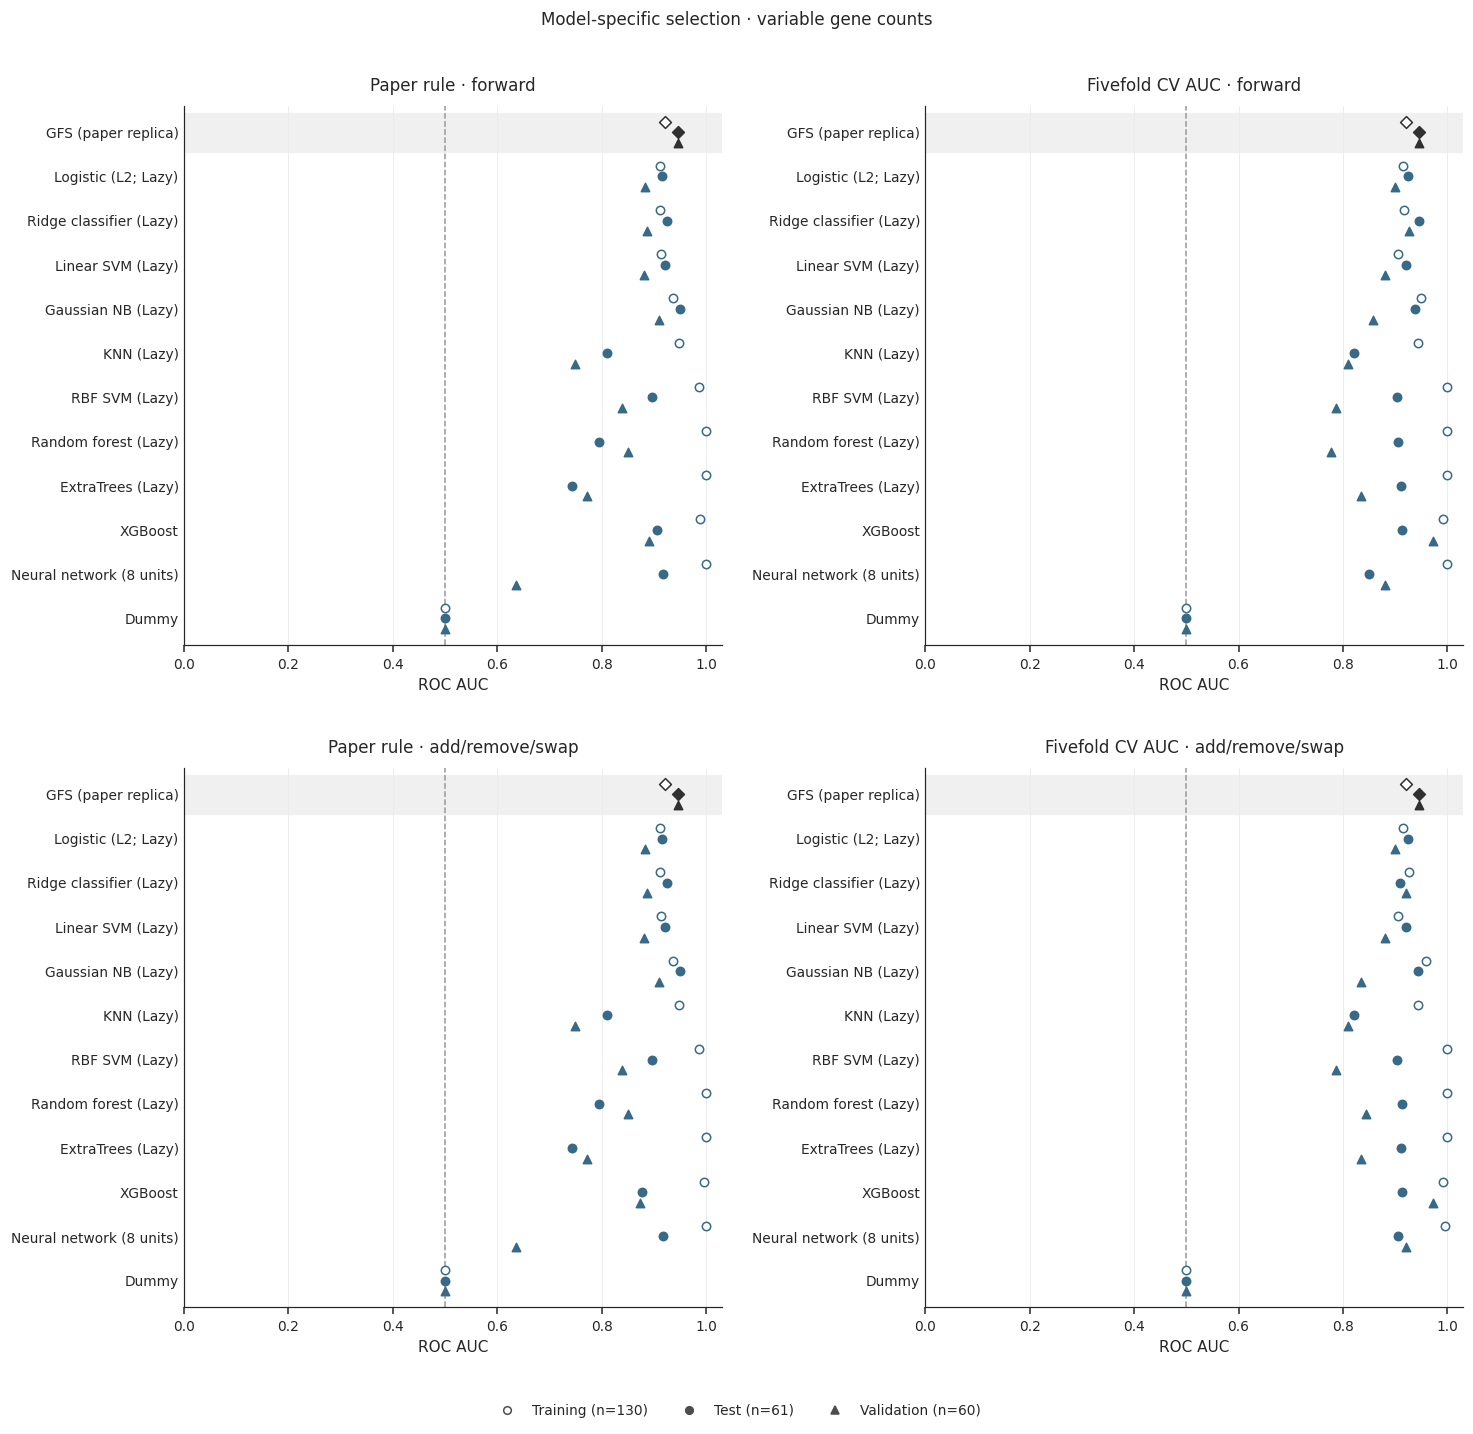

Source,Model,Training AUC,Test AUC,Validation AUC,Selection,Search,Gene count,Selected genes
New,Gaussian NB (Lazy),0.9361,0.9510,0.9097,Paper rule,Forward,6,"GBP5, ENO1, MAP4K4, JMJD1C, TNFAIP2, CAPRIN1"
New,Ridge classifier (Lazy),0.9118,0.9248,0.8869,Paper rule,Forward,4,"GBP5, ENO1, PSMB8, PARP14"
New,Linear SVM (Lazy),0.9137,0.9216,0.8811,Paper rule,Forward,4,"GBP5, ENO1, PSMB8, PLEC"
New,Neural network (8 units),1.0000,0.9183,0.6354,Paper rule,Forward,5,"GBP5, JMJD1C, FECH, FKBP5, TNRC6B"
New,Logistic (L2; Lazy),0.9118,0.9150,0.8823,Paper rule,Forward,3,"GBP5, ENO1, PSMB8"
New,XGBoost,0.9892,0.9052,0.8909,Paper rule,Forward,6,"GBP5, EIF1, CASP4, JMJD1C, IFITM2, BNIP3L"
New,RBF SVM (Lazy),0.9856,0.8965,0.8389,Paper rule,Forward,7,"GBP5, ENO1, LDHA, BNIP3L, IFITM2, DYSF, ADAR"
New,KNN (Lazy),0.9476,0.8105,0.7486,Paper rule,Forward,3,"CASP4, SWAP70, ARRB2"
New,Random forest (Lazy),1.0000,0.7941,0.8503,Paper rule,Forward,1,GBP5
New,ExtraTrees (Lazy),1.0000,0.7435,0.7714,Paper rule,Forward,1,GBP5


In [30]:
gfs_references = pd.concat([
    paper_result.assign(selected_genes=", ".join(paper_model["gene_names"])),
    six_lazy_results.loc[six_lazy_results.model.eq("DummyClassifier")].assign(
        n_features=0, selected_genes="None (chance reference)"
    ),
], ignore_index=True).assign(method="Reference", search="Fixed baseline")

gfs_experiments = [paper_gfs_results, cv_gfs_results, paper_refined_results, cv_refined_results]
model_order = ["GFS", *gfs_templates, "DummyClassifier"]
figure, axes = plt.subplots(2, 2, figsize=(13.5, max(11.5, 0.9 * len(model_order) + 2.5)))
for axis, results, title in zip(
    axes.flat, gfs_experiments,
    ["Paper rule · forward", "Fivefold CV AUC · forward",
     "Paper rule · add/remove/swap", "Fivefold CV AUC · add/remove/swap"],
):
    draw_auc_panel(axis, pd.concat([results, gfs_references], ignore_index=True),
                   title, model_order=model_order)
add_auc_legend(figure)
figure.suptitle("Model-specific selection · variable gene counts", fontsize=11)
figure.tight_layout(rect=(0, 0.05, 1, 0.97), w_pad=2, h_pad=3)
save_figure(figure, "gfs_model_comparison")
plt.show()

gfs_results = pd.concat([
    results.sort_values(["test_auc", "model"], ascending=[False, True])
    for results in [*gfs_experiments, gfs_references]
], ignore_index=True)
gfs_results.to_csv(GFS_OUTPUT / "comparison.csv", index=False)
display_auc_table(gfs_results, extra_columns=("method", "search", "n_features", "selected_genes"))
save_prediction_scores({
    "GFS: paper rule": paper_gfs_predictions,
    "GFS: CV AUC": cv_gfs_predictions,
    "GFS: paper rule + revisions": paper_refined_predictions,
    "GFS: CV AUC + revisions": cv_refined_predictions,
}, "gfs_prediction_scores.csv")


## 8. Save predictions and read the results

Save sample-level scores for all three splits so comparisons can be checked
without refitting.
Calculate the summary from this run. Treat model ranks as descriptive. This
notebook does not test whether an AUC difference is statistically established.

Continue in [gene_cutoff_interpretation.ipynb](gene_cutoff_interpretation.ipynb)
for a compact interpretation of prediction rankings and the effect of adding genes.

In [31]:
prediction_sets = {
    "Six genes": {
        "Paper replica GFS": paper_scores,
        **control_predictions,
        **six_lazy_predictions,
    },
    **broad_predictions,
}
save_prediction_scores(prediction_sets, "prediction_scores.csv")
best_six = ranked_six.iloc[0]
paper_auc = paper_result.test_auc.iloc[0]
unpenalized_auc = control_results.set_index("model").loc[unpenalized_name, "test_auc"]
display(
    Markdown(
        f"**Observed results:** The paper replica has test AUC **{paper_auc:.4f}**. "
        f"The new no-penalty GLM has AUC **{unpenalized_auc:.4f}**. "
        f"The highest six-gene test AUC is **{best_six.test_auc:.4f}**, from **{best_six.model}**. "
        f"That model has training AUC **{best_six.train_auc:.4f}** and "
        f"validation AUC **{best_six.val_auc:.4f}**; the paper replica's validation "
        f"AUC is **{paper_result.val_auc.iloc[0]:.4f}**. "
        "This ranking does not establish superiority or an expression interaction. "
        f"All-gene inputs reduce test AUC in **{(gene_set_change.xs('test')['All minus DE'] < 0).sum()} "
        f"of {len(gene_set_change.xs('test'))}** screened models. More predictors can add noise and change regularization needs."
    )
)
print(f"Current figures and tables: {OUTPUT}")

**Observed results:** The paper replica has test AUC **0.9466**. The new no-penalty GLM has AUC **0.9597**. The highest six-gene test AUC is **0.9608**, from **LinearSVC**. That model has training AUC **0.9202** and validation AUC **0.9451**; the paper replica's validation AUC is **0.9463**. This ranking does not establish superiority or an expression interaction. All-gene inputs reduce test AUC in **7 of 11** screened models. More predictors can add noise and change regularization needs.

Current figures and tables: /local/workdir/amz63/cfRNA_TB/Figure_Output/Gene_Interactions/focused


## Continue with biological interpretation

The completed companion analyses reuse the exported expression and model results, with **existing plasma RNA-source estimates** from `Files_For_Manuscript/discovery_cell_types.tsv` as the primary composition input. That table covers all 251 modeled participants.

1. [Model interpretation](gene_interactions_interpretation.ipynb): SHAP and the SPI1–MNDA–LYZ signal.
2. [Expression patterns](gene_interactions_patterns.ipynb): heatmap, PCA, UMAP, and exploratory patient groups.
3. [Cohort and clinical checks](gene_interactions_cohort_clinical.ipynb): covariate adjustment, cohort consistency, and Xpert Ultra burden.
4. [Pathways](gene_interactions_pathways.ipynb): broad expression programs and selected-gene exclusion from pathway analyses.

Run model interpretation first if its shared exports are missing. These analyses do not require a new deconvolution run or change the classifier comparisons.

[Gene-excluded deconvolution](gene_interactions_deconvolution.ipynb) is an **optional robustness check** comparing matched BayesPrism fits with and without the six XGBoost genes. Separately, `Files_For_Manuscript/cto_wb.txt` contains whole-blood RNA estimates for 60 matched validation participants; it supports an optional paired assay comparison and does not replace the plasma input.